In [ ]:
import pandas as pd

df = pd.read_csv('/content/Fraud_Policy_Claim.csv')

print('Data imported successfully. Displaying the first 5 rows:')
display(df.head())

Data imported successfully. Displaying the first 5 rows:


,Month,Make,AccidentArea,MonthClaimed,Sex,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,...,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,NumberOfCars,Year,BasePolicy
0,Dec,Honda,Urban,Jan,Female,21,Policy Holder,Sport - Liability,Sport,more than 69000,...,none,3 years,26 to 30,No,No,External,none,3 to 4,1994,Liability
1,Jan,Honda,Urban,Jan,Male,34,Policy Holder,Sport - Collision,Sport,more than 69000,...,none,6 years,31 to 35,Yes,No,External,none,1 vehicle,1994,Collision
2,Oct,Honda,Urban,Nov,Male,47,Policy Holder,Sport - Collision,Sport,more than 69000,...,1,7 years,41 to 50,No,No,External,none,1 vehicle,1994,Collision
3,Jun,Toyota,Rural,Jul,Male,65,Third Party,Sedan - Liability,Sport,20000 to 29000,...,1,more than 7,51 to 65,Yes,No,External,more than 5,1 vehicle,1994,Liability
4,Jan,Honda,Urban,Feb,Female,27,Third Party,Sport - Collision,Sport,more than 69000,...,none,5 years,31 to 35,No,No,External,none,1 vehicle,1994,Collision


Removing unncessary columns


In [ ]:
df = df.drop(columns=['Month', 'MonthClaimed', 'PolicyNumber'])

#### Checking for missing and duplicate values

In [ ]:
print(f'Number of duplicate rows found: {df.duplicated().sum()}')

Number of duplicate rows found: 16


In [ ]:
missing_values = df.isnull().sum()
print('Number of missing values per column:')
print(missing_values[missing_values > 0])

Number of missing values per column:
Series([], dtype: int64)


#### Checking the data types of all columns

In [ ]:
print('Data types of each column:')
display(df.dtypes)

Data types of each column:


,0
Make,object
AccidentArea,object
Sex,object
Age,int64
Fault,object
PolicyType,object
VehicleCategory,object
VehiclePrice,object
FraudFound_P,int64
RepNumber,int64


In [ ]:
print('Descriptive statistics for numerical columns:')
display(df[['Age', 'Deductible', 'DriverRating']].describe())

Descriptive statistics for numerical columns:


,Age,Deductible,DriverRating
count,15420.000000,15420.000000,15420.000000
mean,39.855707,407.704280,2.487808
std,13.492377,43.950998,1.119453
min,0.000000,300.000000,1.000000
25%,31.000000,400.000000,1.000000
50%,38.000000,400.000000,2.000000
75%,48.000000,400.000000,3.000000
max,80.000000,700.000000,4.000000


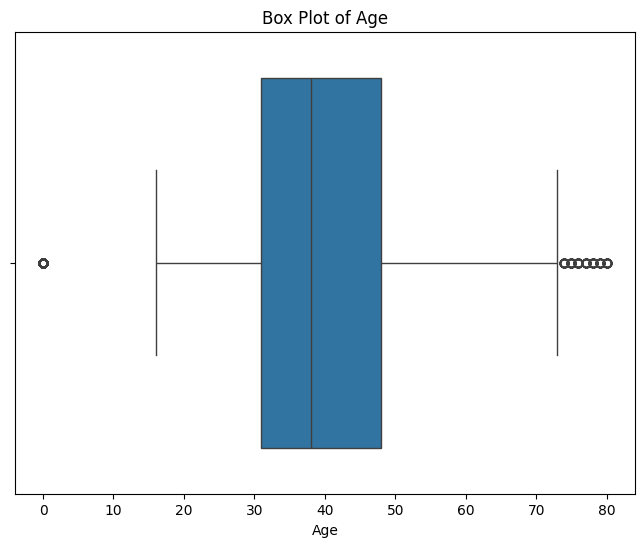

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(x=df['Age'])
plt.title('Box Plot of Age')
plt.xlabel('Age')
plt.show()

In [ ]:
df = df[df['Age'] != 0]

print('Rows with Age = 0 have been removed. Displaying the first 5 rows:')
display(df.head())
print('\nDataFrame Info after cleaning:\n')
df.info()

Rows with Age = 0 have been removed. Displaying the first 5 rows:


,Make,AccidentArea,Sex,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,RepNumber,...,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,NumberOfCars,Year,BasePolicy
0,Honda,Urban,Female,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,12,...,none,3 years,26 to 30,No,No,External,none,3 to 4,1994,Liability
1,Honda,Urban,Male,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,15,...,none,6 years,31 to 35,Yes,No,External,none,1 vehicle,1994,Collision
2,Honda,Urban,Male,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,7,...,1,7 years,41 to 50,No,No,External,none,1 vehicle,1994,Collision
3,Toyota,Rural,Male,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,...,1,more than 7,51 to 65,Yes,No,External,more than 5,1 vehicle,1994,Liability
4,Honda,Urban,Female,27,Third Party,Sport - Collision,Sport,more than 69000,0,3,...,none,5 years,31 to 35,No,No,External,none,1 vehicle,1994,Collision



DataFrame Info after cleaning:

<class 'pandas.core.frame.DataFrame'>
Index: 15100 entries, 0 to 15419
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Make                  15100 non-null  object
 1   AccidentArea          15100 non-null  object
 2   Sex                   15100 non-null  object
 3   Age                   15100 non-null  int64 
 4   Fault                 15100 non-null  object
 5   PolicyType            15100 non-null  object
 6   VehicleCategory       15100 non-null  object
 7   VehiclePrice          15100 non-null  object
 8   FraudFound_P          15100 non-null  int64 
 9   RepNumber             15100 non-null  int64 
 10  Deductible            15100 non-null  int64 
 11  DriverRating          15100 non-null  int64 
 12  Days_Policy_Accident  15100 non-null  object
 13  Days_Policy_Claim     15100 non-null  object
 14  PastNumberOfClaims    15100 non-null  object
 15  AgeOfVeh

#### Finding categorical columns

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns
print('Categorical columns identified:')
print(categorical_cols)

Categorical columns identified:
Index(['Make', 'AccidentArea', 'Sex', 'Fault', 'PolicyType', 'VehicleCategory',
       'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim',
       'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder',
       'PoliceReportFiled', 'WitnessPresent', 'AgentType',
       'NumberOfSuppliments', 'NumberOfCars', 'BasePolicy'],
      dtype='object')


#### Encoding of columns


In [ ]:
# One-hot encoding
categorical_cols = [
    'Make',
    'AccidentArea',
    'Sex',
    'Fault',
    'PolicyType',
    'VehicleCategory',
    'AgentType',
    'BasePolicy',
    'PoliceReportFiled',
    'WitnessPresent'
]

In [ ]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print('DataFrame after one-hot encoding:')
display(df_encoded.head())

DataFrame after one-hot encoding:


,Age,VehiclePrice,FraudFound_P,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,...,PolicyType_Utility - All Perils,PolicyType_Utility - Collision,PolicyType_Utility - Liability,VehicleCategory_Sport,VehicleCategory_Utility,AgentType_Internal,BasePolicy_Collision,BasePolicy_Liability,PoliceReportFiled_Yes,WitnessPresent_Yes
0,21,more than 69000,0,12,300,1,more than 30,more than 30,none,3 years,...,False,False,False,True,False,False,False,True,False,False
1,34,more than 69000,0,15,400,4,more than 30,more than 30,none,6 years,...,False,False,False,True,False,False,True,False,True,False
2,47,more than 69000,0,7,400,3,more than 30,more than 30,1,7 years,...,False,False,False,True,False,False,True,False,False,False
3,65,20000 to 29000,0,4,400,2,more than 30,more than 30,1,more than 7,...,False,False,False,True,False,False,False,True,True,False
4,27,more than 69000,0,3,400,1,more than 30,more than 30,none,5 years,...,False,False,False,True,False,False,True,False,False,False


In [ ]:
for col in [
    'VehiclePrice',
    'Days_Policy_Accident',
    'Days_Policy_Claim',
    'PastNumberOfClaims',
    'AgeOfVehicle',
    'NumberOfSuppliments',
    'NumberOfCars'
]:
    print(f"\n{col}:")
    print(df[col].unique())


VehiclePrice:
['more than 69000' '20000 to 29000' '30000 to 39000' 'less than 20000'
 '40000 to 59000' '60000 to 69000']

Days_Policy_Accident:
['more than 30' '15 to 30' 'none' '1 to 7' '8 to 15']

Days_Policy_Claim:
['more than 30' '15 to 30' '8 to 15']

PastNumberOfClaims:
['none' '1' '2 to 4' 'more than 4']

AgeOfVehicle:
['3 years' '6 years' '7 years' 'more than 7' '5 years' '4 years' '2 years'
 'new']

NumberOfSuppliments:
['none' 'more than 5' '3 to 5' '1 to 2']

NumberOfCars:
['3 to 4' '1 vehicle' '2 vehicles' '5 to 8' 'more than 8']


In [ ]:
past_claims_map = {
    'none': 0,
    '1': 1,
    '2': 2,
    '3 or more': 3
}

df['PastNumberOfClaims'] = df['PastNumberOfClaims'].map(past_claims_map)

In [ ]:
vehicle_price_map = {
    'less than 20000': 0,
    '20000 to 29000': 1,
    '30000 to 39000': 2,
    '40000 to 59000': 3,
    '60000 to 69000': 4,
    'more than 69000': 5
}

df['VehiclePrice'] = df['VehiclePrice'].map(vehicle_price_map)

In [ ]:
days_accident_map = {
    'none': 0,
    '1 to 7': 1,
    '8 to 15': 2,
    '15 to 30': 3,
    'more than 30': 4
}

df['Days_Policy_Accident'] = df['Days_Policy_Accident'].map(days_accident_map)

In [ ]:
days_claim_map = {
    'none': 0,
    '8 to 15': 1,
    '15 to 30': 2,
    'more than 30': 3
}

df['Days_Policy_Claim'] = df['Days_Policy_Claim'].map(days_claim_map)

In [ ]:
past_claims_map = {
    'none': 0,
    '1': 1,
    '2 to 4': 2,
    'more than 4': 3
}

df['PastNumberOfClaims'] = df['PastNumberOfClaims'].map(past_claims_map)

In [ ]:
age_vehicle_map = {
    'new': 0,
    '2 years': 1,
    '3 years': 2,
    '4 years': 3,
    '5 years': 4,
    '6 years': 5,
    '7 years': 6,
    'more than 7': 7
}

df['AgeOfVehicle'] = df['AgeOfVehicle'].map(age_vehicle_map)

In [ ]:
supplements_map = {
    'none': 0,
    '1 to 2': 1,
    '3 to 5': 2,
    'more than 5': 3
}

df['NumberOfSuppliments'] = df['NumberOfSuppliments'].map(supplements_map)

In [ ]:
cars_map = {
    '1 vehicle': 0,
    '2 vehicles': 1,
    '3 to 4': 2,
    '5 to 8': 3,
    'more than 8': 4
}

df['NumberOfCars'] = df['NumberOfCars'].map(cars_map)

#### Standardization of columns

In [ ]:
from sklearn.preprocessing import StandardScaler

# First, ensure all remaining categorical columns are one-hot encoded
# These are the columns that are still of 'object' dtype after previous label encodings
object_cols_for_onehot = df.select_dtypes(include='object').columns.tolist()

# Apply one-hot encoding to these columns in place
df = pd.get_dummies(df, columns=object_cols_for_onehot, drop_first=True)

# Identify numerical columns for scaling (excluding the target variable 'FraudFound_P' and identifiers if any)
numerical_cols_for_scaling = df.drop(columns=['FraudFound_P', 'RepNumber', 'Year']).columns.tolist()

# Initialize the StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to the identified numerical columns
df[numerical_cols_for_scaling] = scaler.fit_transform(df[numerical_cols_for_scaling])

print('Numerical columns have been scaled using StandardScaler. Displaying the first 5 rows:')
display(df.head())
print('\nDescriptive statistics after scaling:')
display(df[numerical_cols_for_scaling].describe())

Numerical columns have been scaled using StandardScaler. Displaying the first 5 rows:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


,Age,VehiclePrice,FraudFound_P,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,...,AgeOfPolicyHolder_31 to 35,AgeOfPolicyHolder_36 to 40,AgeOfPolicyHolder_41 to 50,AgeOfPolicyHolder_51 to 65,AgeOfPolicyHolder_over 65,PoliceReportFiled_Yes,WitnessPresent_Yes,AgentType_Internal,BasePolicy_Collision,BasePolicy_Liability
0,-1.600471,2.369880,0,12,-2.430161,-1.328289,0.096393,0.067556,NaN,-3.236798,...,-0.767009,-0.604691,-0.480045,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,-0.800147,1.449350
1,-0.544340,2.369880,0,15,-0.177387,1.349331,0.096393,0.067556,NaN,-0.629262,...,1.303765,-0.604691,-0.480045,-0.318664,-0.186584,5.919306,-0.07524,-0.127086,1.249771,-0.689964
2,0.511790,2.369880,0,7,-0.177387,0.456791,0.096393,0.067556,NaN,0.239916,...,-0.767009,-0.604691,2.083138,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,1.249771,-0.689964
3,1.974125,-0.527941,0,4,-0.177387,-0.435749,0.096393,0.067556,NaN,1.109095,...,-0.767009,-0.604691,-0.480045,3.138105,-0.186584,5.919306,-0.07524,-0.127086,-0.800147,1.449350
4,-1.113026,2.369880,0,3,-0.177387,-1.328289,0.096393,0.067556,NaN,-1.498441,...,1.303765,-0.604691,-0.480045,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,1.249771,-0.689964



Descriptive statistics after scaling:


,Age,VehiclePrice,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,NumberOfSuppliments,NumberOfCars,...,AgeOfPolicyHolder_31 to 35,AgeOfPolicyHolder_36 to 40,AgeOfPolicyHolder_41 to 50,AgeOfPolicyHolder_51 to 65,AgeOfPolicyHolder_over 65,PoliceReportFiled_Yes,WitnessPresent_Yes,AgentType_Internal,BasePolicy_Collision,BasePolicy_Liability
count,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,0.0,1.510000e+04,1.510000e+04,1.510000e+04,...,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04,1.510000e+04
mean,-1.129339e-16,-1.129339e-17,5.529058e-16,-1.072872e-16,-6.479585e-16,1.200864e-15,NaN,-2.559836e-16,-1.021111e-16,6.305479e-17,...,1.411674e-18,8.281823e-17,-5.646697e-18,1.764593e-17,-4.705581e-18,-7.152483e-17,1.599898e-17,3.952688e-17,6.117255e-18,-7.528930e-18
std,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,NaN,1.000033e+00,1.000033e+00,1.000033e+00,...,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00,1.000033e+00
min,-2.006675e+00,-1.252396e+00,-2.430161e+00,-1.328289e+00,-1.373296e+01,-2.075065e+01,NaN,-4.975155e+00,-9.597101e-01,-2.578378e-01,...,-7.670094e-01,-6.046906e-01,-4.800451e-01,-3.186637e-01,-1.865840e-01,-1.689387e-01,-7.523965e-02,-1.270856e-01,-8.001466e-01,-6.899644e-01
25%,-7.880627e-01,-5.279408e-01,-1.773873e-01,-1.328289e+00,9.639331e-02,6.755575e-02,NaN,-6.292622e-01,-9.597101e-01,-2.578378e-01,...,-7.670094e-01,-6.046906e-01,-4.800451e-01,-3.186637e-01,-1.865840e-01,-1.689387e-01,-7.523965e-02,-1.270856e-01,-8.001466e-01,-6.899644e-01
50%,-1.381363e-01,-5.279408e-01,-1.773873e-01,-4.357487e-01,9.639331e-02,6.755575e-02,NaN,2.399163e-01,-1.599075e-01,-2.578378e-01,...,-7.670094e-01,-6.046906e-01,-4.800451e-01,-3.186637e-01,-1.865840e-01,-1.689387e-01,-7.523965e-02,-1.270856e-01,-8.001466e-01,-6.899644e-01
75%,6.742718e-01,1.965145e-01,-1.773873e-01,4.567913e-01,9.639331e-02,6.755575e-02,NaN,1.109095e+00,1.439698e+00,-2.578378e-01,...,1.303765e+00,1.653738e+00,-4.800451e-01,-3.186637e-01,-1.865840e-01,-1.689387e-01,-7.523965e-02,-1.270856e-01,1.249771e+00,1.449350e+00
max,3.192737e+00,2.369880e+00,6.580933e+00,1.349331e+00,9.639331e-02,6.755575e-02,NaN,1.109095e+00,1.439698e+00,1.013829e+01,...,1.303765e+00,1.653738e+00,2.083138e+00,3.138105e+00,5.359516e+00,5.919306e+00,1.329086e+01,7.868714e+00,1.249771e+00,1.449350e+00


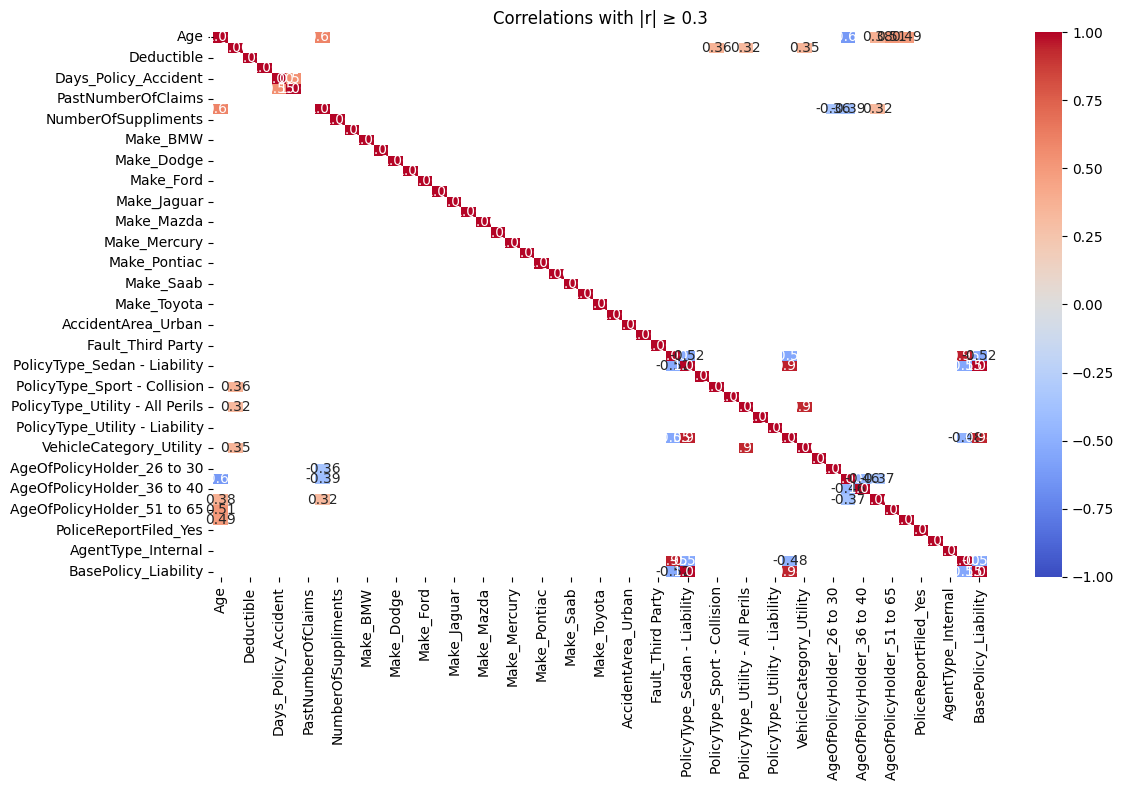

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
corr_matrix = df[numerical_cols_for_scaling].corr()

# Keep only significant/strong correlations
threshold = 0.30

corr_filtered = corr_matrix.where(
    corr_matrix.abs() >= threshold
)

# Plot
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_filtered,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(f'Correlations with |r| ≥ {threshold}')
plt.tight_layout()
plt.show()

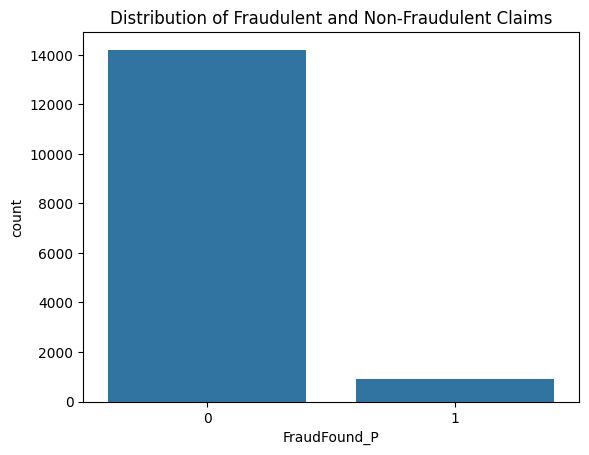

In [ ]:
sns.countplot(x='FraudFound_P', data=df)
plt.title('Distribution of Fraudulent and Non-Fraudulent Claims')
plt.show()

In [ ]:
df['FraudFound_P'].value_counts()
df['FraudFound_P'].value_counts(normalize=True) * 100

,proportion
FraudFound_P,
0,94.092715
1,5.907285


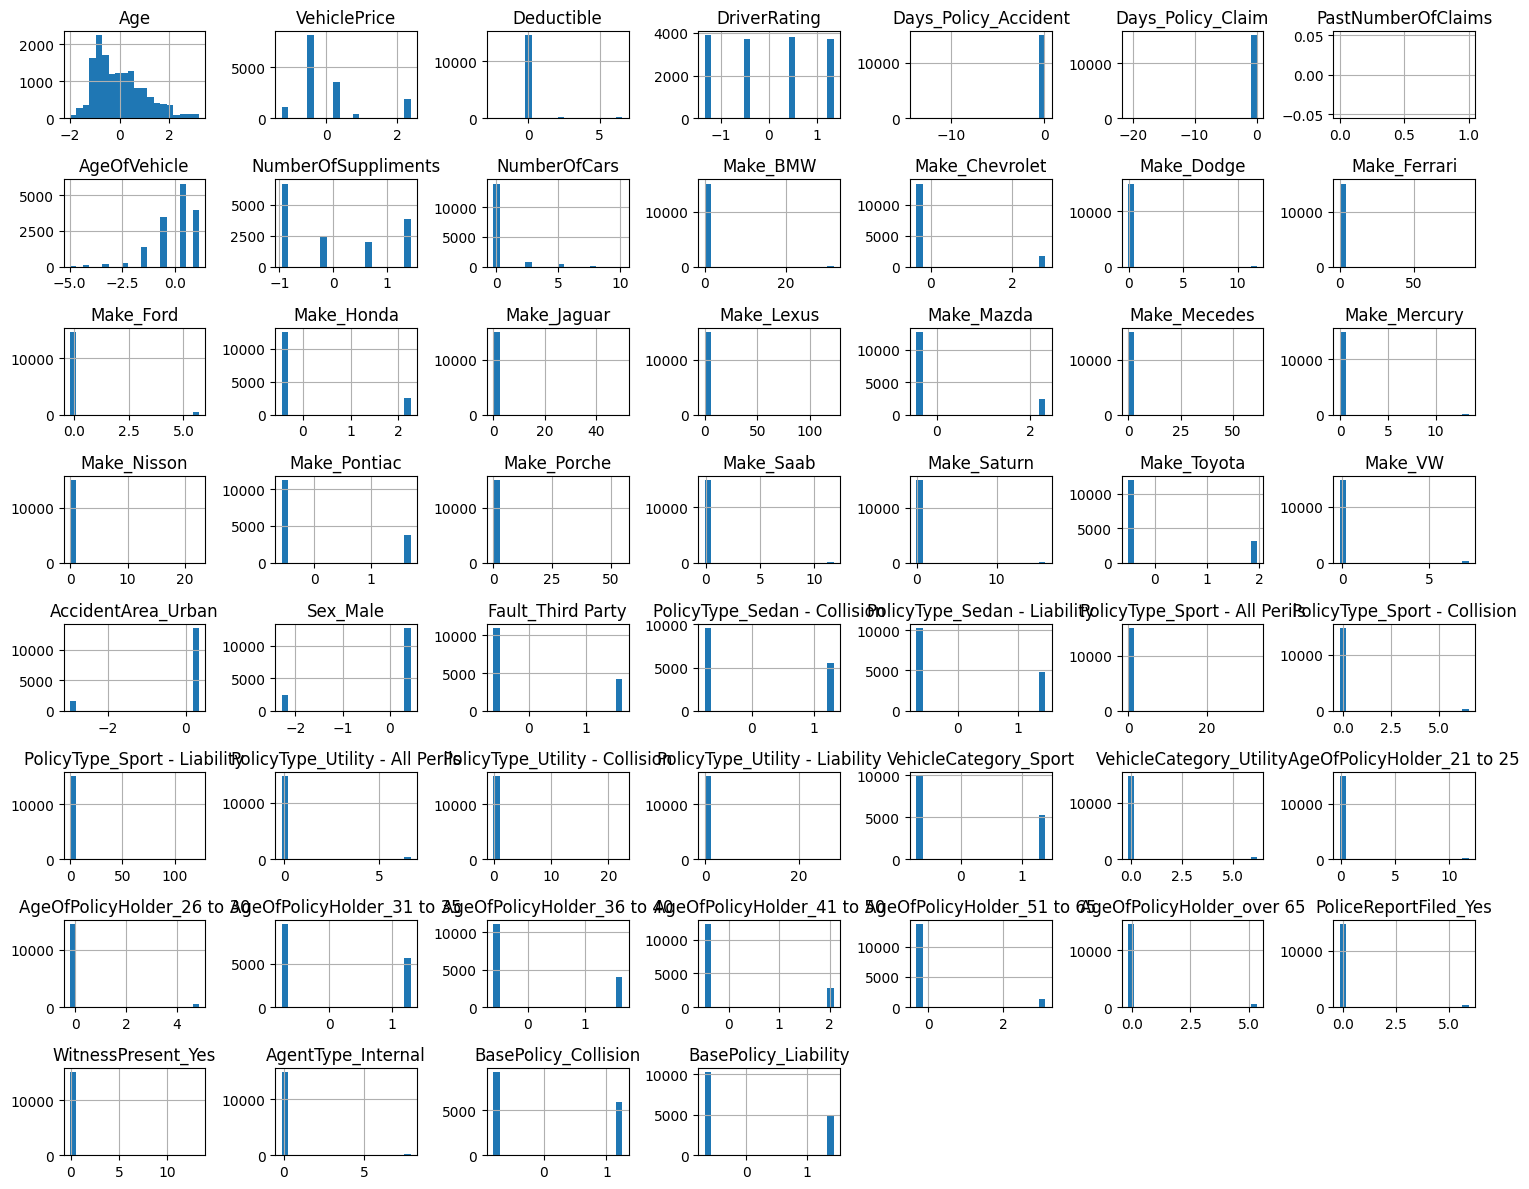

In [ ]:
df[numerical_cols_for_scaling].hist(
    figsize=(15,12),
    bins=20
)

plt.tight_layout()
plt.show()

## Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
# 'FraudFound_P' is the target variable, and we'll drop identifier columns as well.
X = df.drop(columns=['FraudFound_P', 'RepNumber'])
y = df['FraudFound_P']

# Split the data into training and testing sets
# Using a 80/20 split as a common practice, with a random state for reproducibility.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Data split into training and testing sets:')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

print('\nDisplaying the first 5 rows of X_train:')
display(X_train.head())

Data split into training and testing sets:
X_train shape: (12080, 54)
X_test shape: (3020, 54)
y_train shape: (12080,)
y_test shape: (3020,)

Displaying the first 5 rows of X_train:


,Age,VehiclePrice,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,NumberOfSuppliments,NumberOfCars,...,AgeOfPolicyHolder_31 to 35,AgeOfPolicyHolder_36 to 40,AgeOfPolicyHolder_41 to 50,AgeOfPolicyHolder_51 to 65,AgeOfPolicyHolder_over 65,PoliceReportFiled_Yes,WitnessPresent_Yes,AgentType_Internal,BasePolicy_Collision,BasePolicy_Liability
10220,0.674272,-0.527941,-0.177387,-1.328289,0.096393,0.067556,NaN,0.239916,-0.959710,-0.257838,...,-0.767009,-0.604691,2.083138,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,-0.800147,1.449350
11317,-0.138136,-0.527941,-0.177387,-0.435749,0.096393,0.067556,NaN,0.239916,-0.959710,-0.257838,...,-0.767009,1.653738,-0.480045,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,-0.800147,1.449350
12045,1.892884,0.196514,-0.177387,-1.328289,0.096393,0.067556,NaN,1.109095,-0.959710,-0.257838,...,-0.767009,-0.604691,-0.480045,3.138105,-0.186584,-0.168939,-0.07524,-0.127086,-0.800147,1.449350
12070,-0.869304,0.196514,-0.177387,-1.328289,0.096393,0.067556,NaN,-0.629262,1.439698,-0.257838,...,1.303765,-0.604691,-0.480045,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,1.249771,-0.689964
2678,1.080476,0.196514,-0.177387,0.456791,0.096393,0.067556,NaN,1.109095,-0.959710,-0.257838,...,-0.767009,-0.604691,2.083138,-0.318664,-0.186584,-0.168939,-0.07524,-0.127086,-0.800147,-0.689964


### Checking for Multicollinearity with VIF

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import numpy as np

# Drop columns with any NaN values before VIF calculation
X_train_cleaned = X_train.dropna(axis=1)

# Drop columns with zero variance (constant values) from X_train_cleaned initially
constant_columns_before_const = X_train_cleaned.columns[X_train_cleaned.nunique() == 1]
if len(constant_columns_before_const) > 0:
    X_train_cleaned = X_train_cleaned.drop(columns=constant_columns_before_const)
    print(f"Dropped constant columns from X_train_cleaned: {list(constant_columns_before_const)}")

# Check if any columns were dropped due to NaNs
dropped_nan_columns = set(X_train.columns) - set(X_train_cleaned.columns) - set(constant_columns_before_const)
if len(dropped_nan_columns) > 0:
    print(f"Dropped columns with NaN values for VIF calculation: {list(dropped_nan_columns)}")

# List of columns to potentially drop due to multicollinearity with the intercept
# or other one-hot encoded variables.
cols_to_drop_for_vif = []

# We need to drop one dummy variable per original categorical feature group when using an intercept.
# 'PolicyType_Sedan - Liability' was typically dropped by get_dummies(drop_first=True).
# To handle multicollinearity with the added constant, we need to drop one more PolicyType dummy.
# Based on current VIFs, 'PolicyType_Sedan - Collision' is a good candidate.
if 'PolicyType_Sedan - Collision' in X_train_cleaned.columns:
    cols_to_drop_for_vif.append('PolicyType_Sedan - Collision')

# Similarly for VehicleCategory, we drop one more dummy to avoid perfect multicollinearity.
# 'VehicleCategory_Utility' is a good candidate from the problematic VIFs.
if 'VehicleCategory_Utility' in X_train_cleaned.columns:
    cols_to_drop_for_vif.append('VehicleCategory_Utility')

# Execute the drops if any columns were identified
if len(cols_to_drop_for_vif) > 0:
    X_train_cleaned = X_train_cleaned.drop(columns=cols_to_drop_for_vif)
    print(f"Dropped columns to resolve multicollinearity for VIF calculation: {cols_to_drop_for_vif}")

# Add a constant to the DataFrame for VIF calculation
X_train_const = add_constant(X_train_cleaned, has_constant='add')

# Identify and remove columns from X_train_const that have zero variance after adding constant
# This catches dummy variables that become constant (e.g., all zeros) in the training set
# leading to singular matrix issues.
zero_variance_cols_after_const = X_train_const.columns[X_train_const.std() == 0]
if len(zero_variance_cols_after_const) > 0:
    # Ensure we don't accidentally drop the 'const' column if it was identified as zero variance
    # (which it shouldn't be, but as a safeguard)
    zero_variance_cols_after_const = [col for col in zero_variance_cols_after_const if col != 'const']
    if len(zero_variance_cols_after_const) > 0:
        X_train_const = X_train_const.drop(columns=zero_variance_cols_after_const)
        print(f"Dropped zero variance columns from X_train_const (after adding constant): {list(zero_variance_cols_after_const)}")

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = X_train_const.columns

# Handle potential infinite VIF for perfectly correlated features by replacing with infinity
vif_values = []
for i in range(X_train_const.shape[1]):
    try:
        vif_values.append(variance_inflation_factor(X_train_const.values, i))
    except np.linalg.LinAlgError:
        vif_values.append(np.inf) # Assign infinity for perfectly correlated features
vif_data['VIF'] = vif_values

# Sort the VIF values in descending order
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

print('VIF Scores for Features (sorted):\n')
display(vif_data)

Dropped columns with NaN values for VIF calculation: ['PastNumberOfClaims']
Dropped columns to resolve multicollinearity for VIF calculation: ['PolicyType_Sedan - Collision', 'VehicleCategory_Utility']


/tmp/ipykernel_1093/779436180.py:63: UserWarning: The design matrix is poorly conditioned (condition number=5.00e+15). VIF calculations may be numerically unstable.
  vif_values.append(variance_inflation_factor(X_train_const.values, i))
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/sta

VIF Scores for Features (sorted):



/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,feature,VIF
0,PolicyType_Sport - Liability,1.000800e+15
1,PolicyType_Sport - Collision,1.000800e+15
2,PolicyType_Sport - All Perils,1.000800e+15
3,PolicyType_Sedan - Liability,1.000800e+15
4,BasePolicy_Liability,1.000800e+15
5,VehicleCategory_Sport,1.000800e+15
6,PolicyType_Utility - Liability,1.000800e+15
7,AgeOfPolicyHolder_31 to 35,2.381900e+02
8,AgeOfPolicyHolder_36 to 40,2.118083e+02
9,AgeOfPolicyHolder_41 to 50,1.764716e+02


## Fit Logistic Regression Model

### Subtask:
Fit the Logistic Regression model using `X_train_cleaned` and `y_train`, including `class_weight='balanced'`.


In [ ]:
from sklearn.linear_model import LogisticRegression

# Drop 'PolicyType_Sport - Liability' from X_train_cleaned to address multicollinearity
# Create a new DataFrame, X_train_final, for the modified training data.
X_train_final = X_train_cleaned.drop(columns=['PolicyType_Sport - Liability'])

# Instantiate a LogisticRegression model with balanced class weight and random state
log_reg_model = LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

# Fit the logistic regression model to X_train_final and y_train
log_reg_model.fit(X_train_final, y_train)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


**Reasoning**:
The subtask requires fitting a Logistic Regression model. This involves importing the necessary class, preparing the data by dropping a multicollinear column, instantiating the model with specified parameters, and then fitting it to the training data. All these steps are consolidated into a single code block.



In [ ]:
import statsmodels.api as sm

# Add a constant (intercept) to the independent variables for statsmodels
X_train_final_const = sm.add_constant(X_train_final)

# Fit the Logistic Regression model using statsmodels
# Note: statsmodels expects the target variable (y) first
logit_model = sm.Logit(y_train, X_train_final_const)
result = logit_model.fit()

# Print the model summary which includes p-values
print("\nStatsmodels Logistic Regression Model Summary (with p-values):\n")
print(result.summary())

         Current function value: 0.185975
         Iterations: 35

Statsmodels Logistic Regression Model Summary (with p-values):

                           Logit Regression Results                           
Dep. Variable:           FraudFound_P   No. Observations:                12080
Model:                          Logit   Df Residuals:                    12030
Method:                           MLE   Df Model:                           49
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                  0.1716
Time:                        12:26:58   Log-Likelihood:                -2246.6
converged:                      False   LL-Null:                       -2712.0
Covariance Type:            nonrobust   LLR p-value:                3.157e-163
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              17

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
import statsmodels.api as sm
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

X = X_train_final.copy()

# Backward elimination
print("\n--- Starting Backward Elimination ---")
while True:

    # Add intercept
    X_const = sm.add_constant(X, has_constant='add')

    # Fit logistic regression
    # Suppress output for intermediate fits
    with np.errstate(divide='ignore', invalid='ignore'): # Suppress RuntimeWarning
        model = sm.Logit(y_train, X_const).fit(disp=0, maxiter=1000)

    # Get p-values, excluding intercept
    p_values = model.pvalues.drop('const', errors='ignore')

    # If there are no p_values (e.g., only const remains) or all are significant, break
    if p_values.empty or p_values.max() < 0.05:
        break

    # Find variable with highest p-value
    max_p_value = p_values.max()
    worst_feature = p_values.idxmax()

    print(f"Removing: {worst_feature} | p-value: {max_p_value:.4f}")

    # Remove the variable with highest p-value
    X = X.drop(columns=[worst_feature])

print("--- Backward Elimination Complete ---")

# Final model
X_train_selected = X.copy()
X_train_selected_const = sm.add_constant(
    X_train_selected,
    has_constant='add'
)

# Fit the final model with selected features
final_model = sm.Logit(
    y_train,
    X_train_selected_const
).fit() # default disp=True for final model summary

print("\nStatsmodels Logistic Regression Model Summary (after Backward Elimination):\n")
print(final_model.summary())

# --- Evaluation of the Model (with SMOTE options) ---

def train_evaluate_statsmodel(X_train_base, y_train_base, X_test_base, y_test_base, smote_strategy=None, model_name="Statsmodels Logit"):
    """
    Applies SMOTE (if specified), trains a statsmodels Logit model,
    and evaluates its performance.
    X_train_base and X_test_base should be the feature sets *after* feature selection,
    but *before* adding the constant.
    """
    X_resampled, y_resampled = X_train_base.copy(), y_train_base.copy()

    if smote_strategy is not None:
        smote = SMOTE(sampling_strategy=smote_strategy, random_state=42)
        X_resampled, y_resampled = smote.fit_resample(X_train_base, y_train_base)
        print(f"\nSMOTE applied with strategy: {smote_strategy}. New class distribution: {pd.Series(y_resampled).value_counts()}")

    # Add constant to resampled training data
    X_resampled_const = sm.add_constant(X_resampled, has_constant='add')

    # Fit the statsmodels Logit model
    # Handle ConvergenceWarning for the inner fits
    with np.errstate(divide='ignore', invalid='ignore'): # Suppress RuntimeWarning
        model = sm.Logit(y_resampled, X_resampled_const).fit(disp=0, maxiter=1000) # Increased maxiter for convergence

    # Prepare test data with constant and match column order
    # X_test_base here is already filtered to X_train_selected.columns
    X_test_const_aligned = sm.add_constant(X_test_base.copy(), has_constant='add')

    # Ensure test data has all columns present in the trained model (X_resampled_const)
    # Fill missing columns (e.g., one-hot encoded categories not present in test) with 0
    missing_in_test_cols = set(X_resampled_const.columns) - set(X_test_const_aligned.columns)
    for col in missing_in_test_cols:
        X_test_const_aligned[col] = 0

    # Drop extra columns from test data that were not in the resampled training data
    extra_in_test_cols = set(X_test_const_aligned.columns) - set(X_resampled_const.columns)
    X_test_const_aligned = X_test_const_aligned.drop(columns=list(extra_in_test_cols))

    # Ensure column order matches exactly
    X_test_const_aligned = X_test_const_aligned[X_resampled_const.columns]

    # Make predictions (probabilities) on the test set
    y_pred_proba = model.predict(X_test_const_aligned)

    # Convert probabilities to binary predictions using a threshold (e.5) if not provided by model
    y_pred = (y_pred_proba >= 0.5).astype(int)

    report = classification_report(y_test_base, y_pred, output_dict=True, zero_division=0)

    # Handle cases where Class 1 might not be present in predictions/true values
    precision_1 = report['1']['precision'] if '1' in report and 'precision' in report['1'] else 0
    recall_1 = report['1']['recall'] if '1' in report and 'recall' in report['1'] else 0
    f1_1 = report['1']['f1-score'] if '1' in report and 'f1-score' in report['1'] else 0

    roc_auc = roc_auc_score(y_test_base, y_pred_proba)

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_base, y_pred),
        'Precision (Class 1)': precision_1,
        'Recall (Class 1)': recall_1,
        'F1-Score (Class 1)': f1_1,
        'ROC AUC': roc_auc
    }

# Prepare X_test_selected by filtering X_test with the same columns as X_train_selected
X_test_selected = X_test[X_train_selected.columns]

# --- Evaluation of the Original Statsmodels Model (no SMOTE, i.e., final_model from backward elimination) ---
# Ensure X_test_selected has a constant added for statsmodels prediction
X_test_selected_const = sm.add_constant(X_test_selected, has_constant='add')

# Make predictions (probabilities) on the test set using the final_model
y_pred_proba_original = final_model.predict(X_test_selected_const)
y_pred_original = (y_pred_proba_original >= 0.5).astype(int)

report_original = classification_report(y_test, y_pred_original, output_dict=True, zero_division=0)

original_statsmodel_metrics = {
    'Model': 'Statsmodels Original (No SMOTE)',
    'Accuracy': accuracy_score(y_test, y_pred_original),
    'Precision (Class 1)': report_original['1']['precision'] if '1' in report_original and 'precision' in report_original['1'] else 0,
    'Recall (Class 1)': report_original['1']['recall'] if '1' in report_original and 'recall' in report_original['1'] else 0,
    'F1-Score (Class 1)': report_original['1']['f1-score'] if '1' in report_original and 'f1-score' in report_original['1'] else 0,
    'ROC AUC': roc_auc_score(y_test, y_pred_proba_original)
}

results_sm = [original_statsmodel_metrics]

# Define SMOTE strategies and their corresponding names for statsmodels
smote_strategies_sm = {
    'Statsmodels SMOTE (50:50)': 1.0, # Minority class becomes equal to majority class
    'Statsmodels SMOTE (45:55)': 0.45, # Minority class becomes 45% of majority class
    'Statsmodels SMOTE (55:45)': 0.55  # Minority class becomes 55% of majority class
}

# Train and evaluate models with different SMOTE strategies
for name, strategy in smote_strategies_sm.items():
    print(f"\n--- Training and Evaluating {name} ---")
    metrics = train_evaluate_statsmodel(X_train_selected, y_train, X_test_selected, y_test, smote_strategy=strategy, model_name=name)
    results_sm.append(metrics)

# Create a DataFrame to compare the results
comparison_df_sm = pd.DataFrame(results_sm)
print("\n--- Statsmodels Model Comparison Table with SMOTE ---")
display(comparison_df_sm.set_index('Model'))


--- Starting Backward Elimination ---


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Removing: VehicleCategory_Sport | p-value: 1.0000


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Removing: PolicyType_Utility - Liability | p-value: 1.0000


...

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Removing: PolicyType_Sedan - Liability | p-value: 0.9996


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Removing: AgeOfPolicyHolder_26 to 30 | p-value: 0.9995
Removing: Days_Policy_Claim | p-value: 0.9461
Removing: PolicyType_Utility - Collision | p-value: 0.9460
Removing: Age | p-value: 0.9327
Removing: Year | p-value: 0.8210
Removing: Make_Saab | p-value: 0.7571
Removing: Make_Ford | p-value: 0.6339
Removing: Make_Saturn | p-value: 0.6446
Removing: Make_Mecedes | p-value: 0.5594
Removing: WitnessPresent_Yes | p-value: 0.4799
Removing: NumberOfCars | p-value: 0.4652
Removing: AgeOfPolicyHolder_over 65 | p-value: 0.3881
Removing: AgeOfPolicyHolder_51 to 65 | p-value: 0.5637
Removing: AgeOfPolicyHolder_41 to 50 | p-value: 0.4751
Removing: AgentType_Internal | p-value: 0.3634
Removing: Make_Nisson | p-value: 0.3035
Removing: DriverRating | p-value: 0.2950
Removing: VehiclePrice | p-value: 0.2964
Removing: PolicyType_Utility - All Perils | p-value: 0.2763
Removing: Make_Dodge | p-value: 0.2179
Removing: Make_Mercury | p-value: 0.1633
Removing: AgeOfPolicyHolder_21 to 25 | p-value: 0.1327
Re

,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC AUC
Model,,,,,
Statsmodels Original (No SMOTE),0.941060,0.000000,0.000000,0.000000,0.784437
Statsmodels SMOTE (50:50),0.618874,0.121401,0.876404,0.213260,0.784639
Statsmodels SMOTE (45:55),0.828146,0.159681,0.449438,0.235641,0.784265
Statsmodels SMOTE (55:45),0.753642,0.137179,0.601124,0.223382,0.784839


The SMOTE 50:50 shows highest recall which is necessary in case of fraud detectioin. Hnece, we willl go ahead with SMOTE 50:50.

## Checking SMOTE 50:50 for test data


In [ ]:
# Features selected through backward elimination
X_train_selected = X_train[X_train_selected.columns].copy()
X_test_selected = X_test[X_train_selected.columns].copy()

print("Selected features:", X_train_selected.shape[1])
print("Training shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)

Selected features: 13
Training shape: (12080, 13)
Testing shape: (3020, 13)


In [ ]:
from imblearn.over_sampling import SMOTE
import pandas as pd

smote = SMOTE(
    sampling_strategy=1.0,   # 50:50
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_selected,
    y_train
)

print("Original training distribution:")
print(y_train.value_counts())

print("\nAfter SMOTE 50:50:")
print(pd.Series(y_train_smote).value_counts())

Original training distribution:
FraudFound_P
0    11366
1      714
Name: count, dtype: int64

After SMOTE 50:50:
FraudFound_P
0    11366
1    11366
Name: count, dtype: int64


In [ ]:
import statsmodels.api as sm

# Add constant to SMOTE-resampled training data
X_train_smote_const = sm.add_constant(
    X_train_smote,
    has_constant='add'
)

# Train final model
final_smote_model = sm.Logit(
    y_train_smote,
    X_train_smote_const
).fit(
    maxiter=1000
)

print(final_smote_model.summary())

Optimization terminated successfully.
         Current function value: 0.505230
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           FraudFound_P   No. Observations:                22732
Model:                          Logit   Df Residuals:                    22718
Method:                           MLE   Df Model:                           13
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                  0.2711
Time:                        12:28:27   Log-Likelihood:                -11485.
converged:                       True   LL-Null:                       -15757.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -1.0409      0.025    -41.137      0.000

In [ ]:
# Add constant to untouched test data
X_test_selected_const = sm.add_constant(
    X_test_selected,
    has_constant='add'
)

# Make sure test columns exactly match training columns
X_test_selected_const = X_test_selected_const[
    X_train_smote_const.columns
]

# Predict fraud probabilities
y_pred_proba = final_smote_model.predict(
    X_test_selected_const
)

# Convert probabilities to 0/1 using 0.5 threshold
y_pred = (y_pred_proba >= 0.5).astype(int)

print("First 10 predicted probabilities:")
print(y_pred_proba.head(10))

print("\nFirst 10 predictions:")
print(y_pred.head(10))

First 10 predicted probabilities:
1309     0.076775
5876     0.667150
8389     0.075784
3752     0.678020
14515    0.581033
8673     0.169865
12926    0.075046
9188     0.653188
4767     0.689251
4846     0.679825
dtype: float64

First 10 predictions:
1309     0
5876     1
8389     0
3752     1
14515    1
8673     0
12926    0
9188     1
4767     1
4846     1
dtype: int64


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display results
print("===== FINAL TEST SET EVALUATION =====")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))

===== FINAL TEST SET EVALUATION =====
Accuracy  : 0.6189
Precision : 0.1214
Recall    : 0.8764
F1-Score  : 0.2133
ROC-AUC   : 0.7846

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.99      0.60      0.75      2842
           1       0.12      0.88      0.21       178

    accuracy                           0.62      3020
   macro avg       0.55      0.74      0.48      3020
weighted avg       0.94      0.62      0.72      3020


===== CONFUSION MATRIX =====
[[1713 1129]
 [  22  156]]


## DECISION TREE

In [ ]:
X_train_dt = X_train_selected.copy()
X_test_dt = X_test_selected.copy()

print("Training shape:", X_train_dt.shape)
print("Testing shape:", X_test_dt.shape)

Training shape: (12080, 13)
Testing shape: (3020, 13)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train_dt,
    y_train
)

DecisionTreeClassifier(random_state=42)

In [ ]:
y_pred_dt = dt_model.predict(X_test_dt)

y_prob_dt = dt_model.predict_proba(X_test_dt)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

print("===== DECISION TREE — ORIGINAL DATA =====")
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1-Score  : {dt_f1:.4f}")
print(f"ROC-AUC   : {dt_roc_auc:.4f}")

print("\n===== Classification Report =====")
print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))

print("\n===== Confusion Matrix =====")
print(confusion_matrix(y_test, y_pred_dt))

===== DECISION TREE — ORIGINAL DATA =====
Accuracy  : 0.9404
Precision : 0.4615
Recall    : 0.0674
F1-Score  : 0.1176
ROC-AUC   : 0.7637

===== Classification Report =====
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      2842
           1       0.46      0.07      0.12       178

    accuracy                           0.94      3020
   macro avg       0.70      0.53      0.54      3020
weighted avg       0.92      0.94      0.92      3020


===== Confusion Matrix =====
[[2828   14]
 [ 166   12]]


The Decision Tree gave **94.04% accuracy** on the original imbalanced test data. However, this accuracy is not enough to judge the model because there were much fewer fraud cases than non-fraud cases. Out of **178 actual fraud cases, the model correctly identified only 12**, while it missed **166 cases**. This resulted in a very low recall of **6.74%**.

The model had a precision of **46.15%**, meaning that when it predicted a claim as fraud, it was correct in about 46% of the cases. However, the low recall resulted in a low **F1-score of 11.76%**. The **ROC-AUC of 0.7637** shows that the model has some ability to differentiate between fraudulent and non-fraudulent claims, but its performance in actually identifying fraud cases needs improvement.


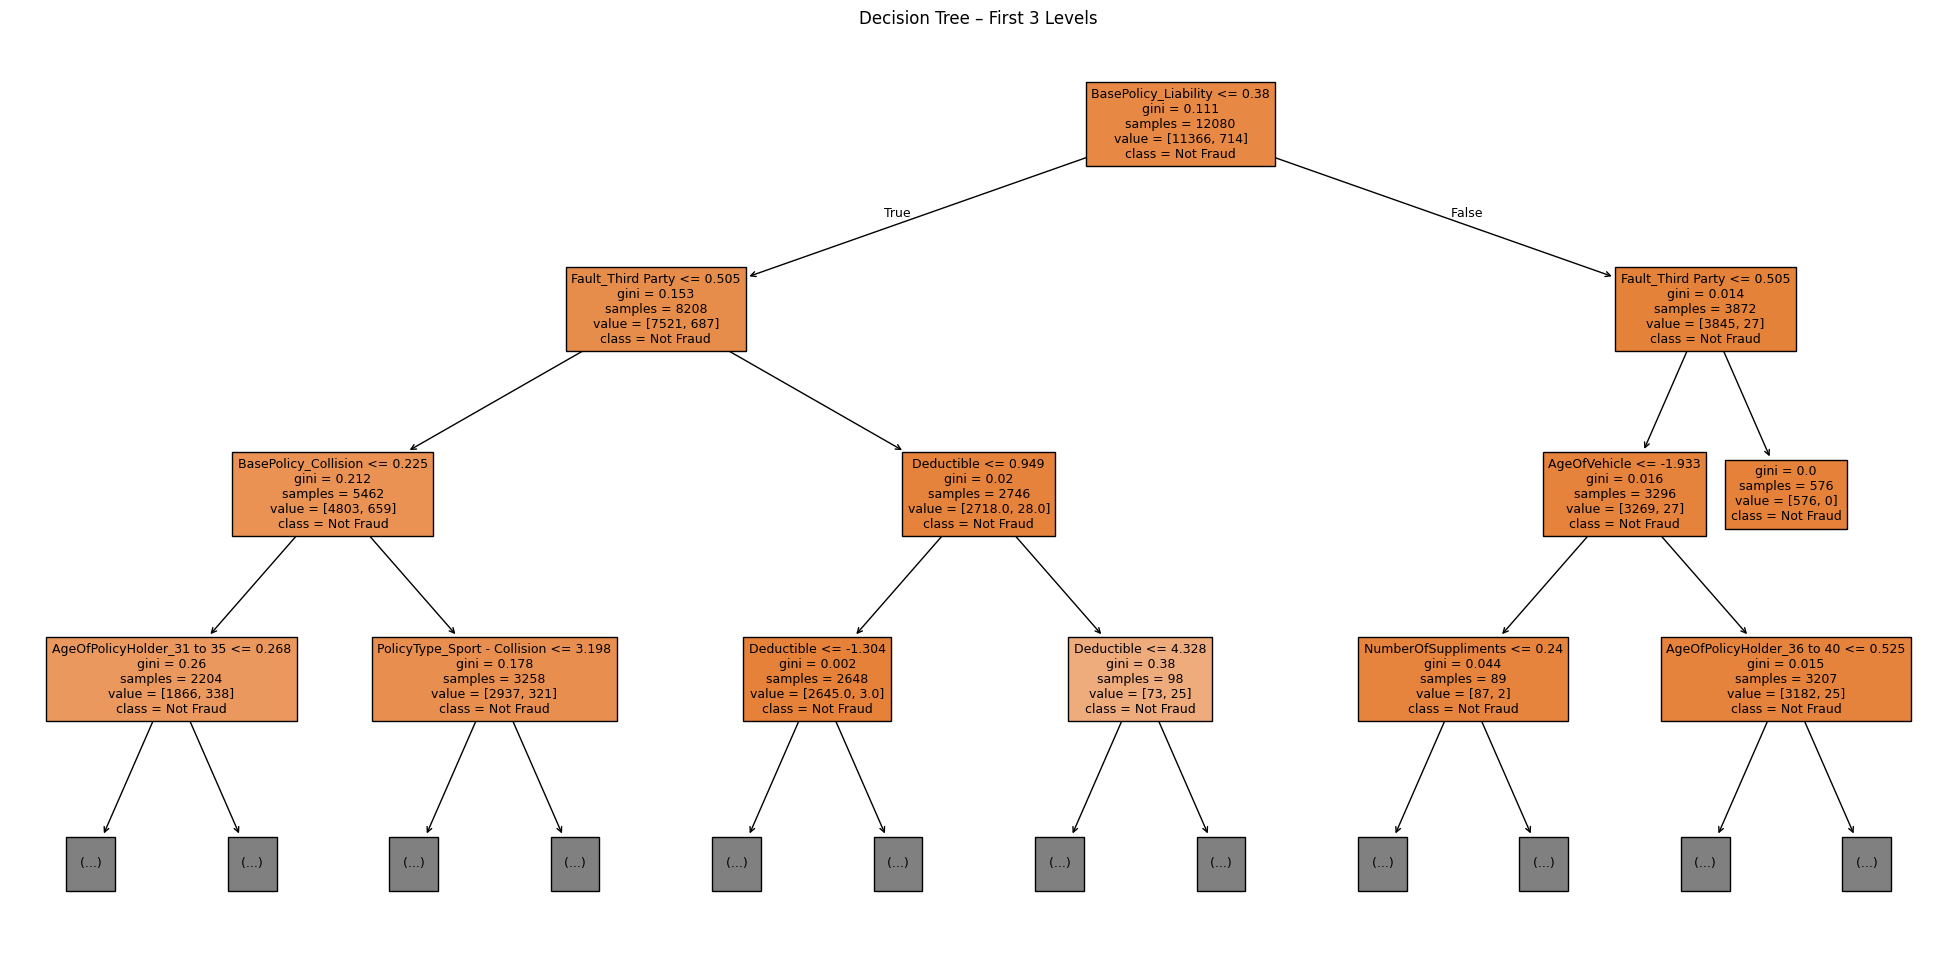

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 12))

plot_tree(
    dt_model,
    feature_names=X_train_dt.columns,
    class_names=['Not Fraud', 'Fraud'],
    filled=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree – First 3 Levels")
plt.show()

In [ ]:
feature_importance_dt = pd.DataFrame({
    'Feature': X_train_dt.columns,
    'Importance': dt_model.feature_importances_
})

feature_importance_dt = feature_importance_dt.sort_values(
    'Importance',
    ascending=False
)

display(feature_importance_dt)

,Feature,Importance
6,Fault_Third Party,0.142368
0,Deductible,0.138325
1,AgeOfVehicle,0.133219
2,NumberOfSuppliments,0.117915
8,AgeOfPolicyHolder_31 to 35,0.101155
12,BasePolicy_Liability,0.098758
4,AccidentArea_Urban,0.071164
9,AgeOfPolicyHolder_36 to 40,0.060266
5,Sex_Male,0.043675
11,BasePolicy_Collision,0.025203


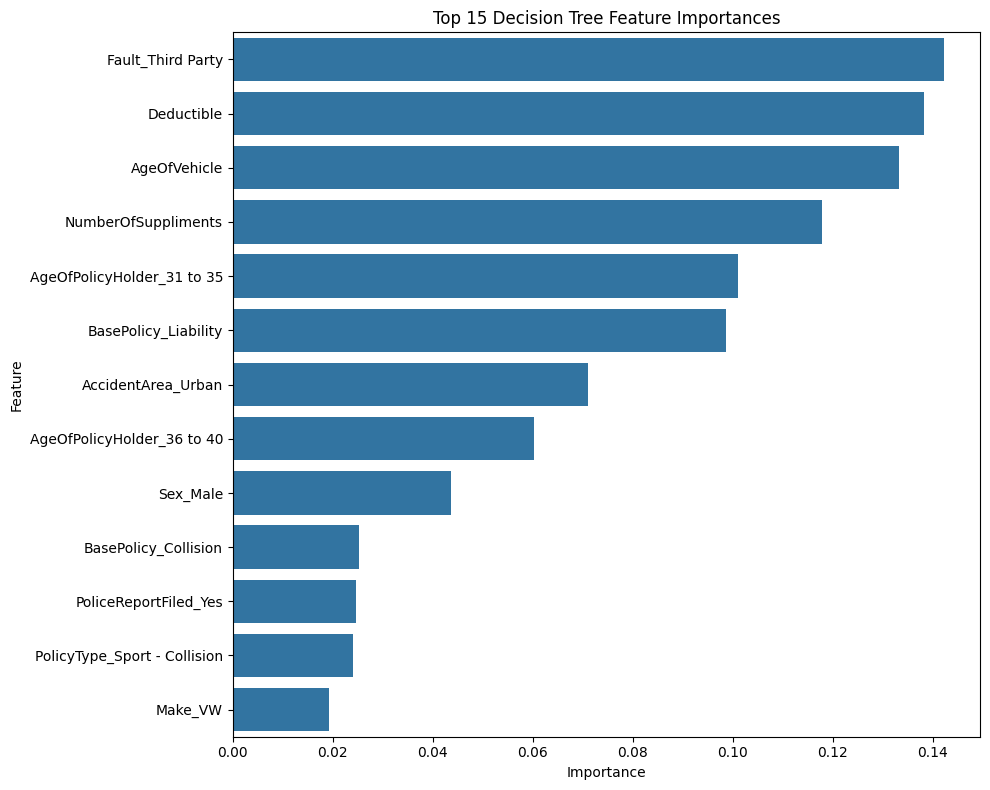

In [ ]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance_dt.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Decision Tree Feature Importances')
plt.tight_layout()
plt.show()

The Decision Tree identified Fault_Third Party, Deductible, AgeOfVehicle, and NumberOfSuppliments as the most influential predictors of claim fraud classification. Policyholder age categories and base policy type also made substantial contributions. In contrast, individual features such as Make_VW, PolicyType_Sport - Collision, and PoliceReportFiled_Yes had relatively lower importance in the fitted tree. These importance values indicate the features that contributed most to the model's predictive decisions and should not be interpreted as causal relationships.

## RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_selected,
    y_train
)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
# Predicted class
y_pred_rf = rf_model.predict(X_test_selected)

# Probability of Class 1 (Fraud)
y_prob_rf = rf_model.predict_proba(X_test_selected)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("===== RANDOM FOREST — ORIGINAL DATA =====")
print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\n===== Classification Report =====")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("\n===== Confusion Matrix =====")
print(confusion_matrix(y_test, y_pred_rf))

===== RANDOM FOREST — ORIGINAL DATA =====
Accuracy  : 0.9394
Precision : 0.3913
Recall    : 0.0506
F1-Score  : 0.0896
ROC-AUC   : 0.7887

===== Classification Report =====
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      2842
           1       0.39      0.05      0.09       178

    accuracy                           0.94      3020
   macro avg       0.67      0.52      0.53      3020
weighted avg       0.91      0.94      0.92      3020


===== Confusion Matrix =====
[[2828   14]
 [ 169    9]]


The Random Forest achieved 93.94% accuracy, but its fraud detection performance was low. It correctly identified only 9 out of 178 fraudulent claims, giving a recall of 5.06%, while missing 169 fraud cases. Its precision was 39.13% and F1-score was 8.96%. The ROC-AUC of 0.7887 indicates that the model has some ability to distinguish between fraud and non-fraud, but the class imbalance significantly limits fraud detection at the default threshold.

In [ ]:
rf_importance = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    'Importance',
    ascending=False
)

display(rf_importance)

,Feature,Importance
1,AgeOfVehicle,0.219322
2,NumberOfSuppliments,0.143898
12,BasePolicy_Liability,0.125909
6,Fault_Third Party,0.117978
0,Deductible,0.109550
11,BasePolicy_Collision,0.051250
8,AgeOfPolicyHolder_31 to 35,0.048727
9,AgeOfPolicyHolder_36 to 40,0.045177
5,Sex_Male,0.041899
4,AccidentArea_Urban,0.037153


The most important features were AgeOfVehicle (21.93%), NumberOfSuppliments (14.39%), BasePolicy_Liability (12.59%), and Fault_Third Party (11.80%). This indicates that vehicle age, number of supplements, policy type, and fault details contributed most to the model’s fraud predictions. Make_VW (1.17%) had the lowest importance among the selected features.

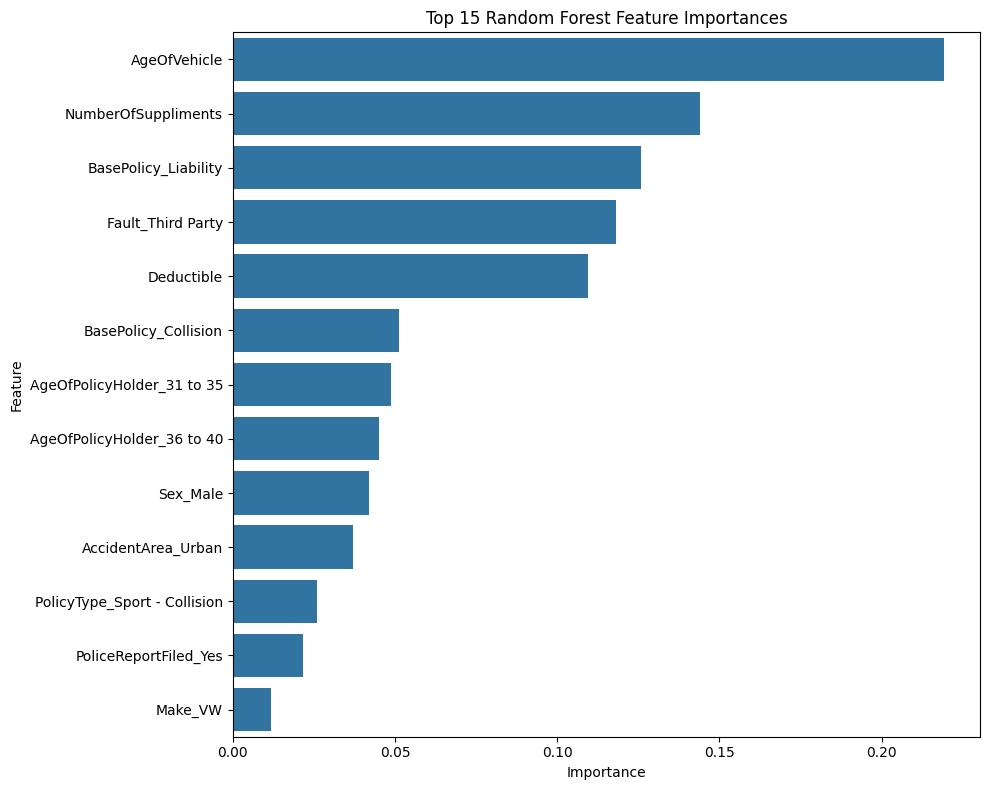

In [ ]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Random Forest Feature Importances')
plt.tight_layout()
plt.show()

## Listing significant variables in Logistic Regression, Decision Tree and Random Forest

In [ ]:
import pandas as pd

variable_summary = pd.DataFrame({
    'Variable': [
        'AgeOfVehicle',
        'NumberOfSuppliments',
        'Fault_Third Party',
        'BasePolicy_Liability',
        'Deductible',
        'AgeOfPolicyHolder',
        'AccidentArea_Urban',
        'BasePolicy_Collision',
        'Sex_Male',
        'PolicyType_Sport-Collision',
        'PoliceReportFiled_Yes',
        'Make_VW'
    ],

    'Logistic Regression': [
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected',
        'Significant/Selected'
    ],

    'Decision Tree': [
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important'
    ],

    'Random Forest': [
        'Most Important',
        'Highly Important',
        'Highly Important',
        'Highly Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Important',
        'Moderate/Low',
        'Lower Importance',
        'Lowest Importance'
    ],

    'Overall': [
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Common Variable',
        'Supported',
        'Supported',
        'Supported'
    ]
})

# Display the table
display(variable_summary)

,Variable,Logistic Regression,Decision Tree,Random Forest,Overall
0,AgeOfVehicle,Significant/Selected,Important,Most Important,Common Variable
1,NumberOfSuppliments,Significant/Selected,Important,Highly Important,Common Variable
2,Fault_Third Party,Significant/Selected,Important,Highly Important,Common Variable
3,BasePolicy_Liability,Significant/Selected,Important,Highly Important,Common Variable
4,Deductible,Significant/Selected,Important,Important,Common Variable
5,AgeOfPolicyHolder,Significant/Selected,Important,Important,Common Variable
6,AccidentArea_Urban,Significant/Selected,Important,Important,Common Variable
7,BasePolicy_Collision,Significant/Selected,Important,Important,Common Variable
8,Sex_Male,Significant/Selected,Important,Important,Common Variable
9,PolicyType_Sport-Collision,Significant/Selected,Important,Moderate/Low,Supported


In [ ]:
summary_table = pd.DataFrame({
    'Key Variable': [
        'AgeOfVehicle',
        'NumberOfSuppliments',
        'Fault_Third Party',
        'BasePolicy_Liability',
        'Deductible',
        'AgeOfPolicyHolder',
        'AccidentArea_Urban',
        'BasePolicy_Collision',
        'Sex_Male'
    ],
    'Identified Across Models': [
        'Yes', 'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'Yes', 'Yes', 'Yes'
    ]
})

display(summary_table)

,Key Variable,Identified Across Models
0,AgeOfVehicle,Yes
1,NumberOfSuppliments,Yes
2,Fault_Third Party,Yes
3,BasePolicy_Liability,Yes
4,Deductible,Yes
5,AgeOfPolicyHolder,Yes
6,AccidentArea_Urban,Yes
7,BasePolicy_Collision,Yes
8,Sex_Male,Yes


### Deploying K-Means Clustering of key variables identified across models

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

# Key variables identified across the three models
cluster_features = [
    'AgeOfVehicle',
    'NumberOfSuppliments',
    'Fault_Third Party',
    'Deductible',
    'BasePolicy_Liability',
    'BasePolicy_Collision',
    'AgeOfPolicyHolder_31 to 35',
    'AgeOfPolicyHolder_36 to 40',
    'Sex_Male',
    'AccidentArea_Urban',
    'PolicyType_Sport - Collision',
    'PoliceReportFiled_Yes'
]

X_cluster = df[cluster_features].copy()

print(X_cluster.head())

   AgeOfVehicle  NumberOfSuppliments  Fault_Third Party  Deductible  \
0     -3.236798            -0.959710          -0.615421   -2.430161   
1     -0.629262            -0.959710          -0.615421   -0.177387   
2      0.239916            -0.959710          -0.615421   -0.177387   
3      1.109095             1.439698           1.624903   -0.177387   
4     -1.498441            -0.959710           1.624903   -0.177387   

   BasePolicy_Liability  BasePolicy_Collision  AgeOfPolicyHolder_31 to 35  \
0              1.449350             -0.800147                   -0.767009   
1             -0.689964              1.249771                    1.303765   
2             -0.689964              1.249771                   -0.767009   
3              1.449350             -0.800147                   -0.767009   
4             -0.689964              1.249771                    1.303765   

   AgeOfPolicyHolder_36 to 40  Sex_Male  AccidentArea_Urban  \
0                   -0.604691 -2.289032        

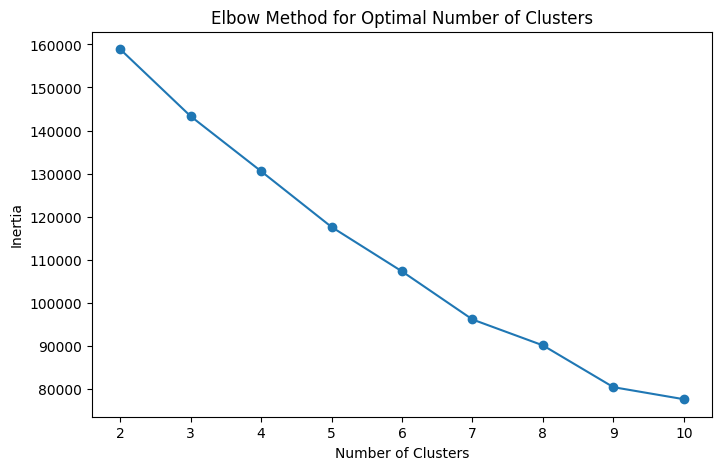

In [ ]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_cluster)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    score = silhouette_score(X_cluster, cluster_labels)
    silhouette_scores.append(score)

# Display scores
silhouette_results = pd.DataFrame({
    'Number of Clusters': range(2, 11),
    'Silhouette Score': silhouette_scores
})

display(silhouette_results)

,Number of Clusters,Silhouette Score
0,2,0.152445
1,3,0.166034
2,4,0.183963
3,5,0.182311
4,6,0.184041
5,7,0.192488
6,8,0.196441
7,9,0.225412
8,10,0.224648


The highest score of 0.2254 is obtained for 9 clusters. Therefore, 9 clusters will be selected as the optimal number for K-Means clustering.

In [ ]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_cluster)

X_cluster['Cluster'] = cluster_labels

print(X_cluster['Cluster'].value_counts().sort_index())

Cluster
0    2280
1    2603
2    2120
3     344
4    2587
5     397
6    3000
7    1461
8     308
Name: count, dtype: int64


In [ ]:
cluster_profile = X_cluster.groupby('Cluster')[cluster_features].mean()

display(cluster_profile.round(2))

,AgeOfVehicle,NumberOfSuppliments,Fault_Third Party,Deductible,BasePolicy_Liability,BasePolicy_Collision,AgeOfPolicyHolder_31 to 35,AgeOfPolicyHolder_36 to 40,Sex_Male,AccidentArea_Urban,PolicyType_Sport - Collision,PoliceReportFiled_Yes
Cluster,,,,,,,,,,,,
0,-0.69,-0.07,0.06,-0.15,-0.69,1.25,0.99,-0.60,-0.11,0.34,-0.15,-0.17
1,0.43,0.10,-0.32,-0.12,1.45,-0.80,-0.77,0.48,-0.01,0.34,-0.15,-0.17
2,0.22,0.02,0.12,-0.13,-0.69,0.34,-0.77,1.65,0.02,0.34,-0.15,-0.17
3,-0.60,-0.41,0.55,-0.09,-0.69,1.25,-0.01,-0.20,0.13,0.16,6.55,0.01
4,0.79,0.03,0.16,-0.14,-0.69,0.12,-0.77,-0.60,0.23,0.34,-0.15,-0.17
5,-0.04,0.05,0.17,-0.14,-0.24,0.18,0.02,-0.08,-0.06,0.04,-0.15,5.92
6,-0.68,-0.07,-0.05,-0.15,0.53,-0.80,1.15,-0.60,-0.18,0.34,-0.15,-0.17
7,0.02,0.07,-0.04,-0.14,-0.17,0.10,-0.01,0.02,0.08,-2.96,-0.15,-0.17
8,0.61,0.03,-0.04,6.58,0.12,-0.13,-0.36,0.19,0.12,0.03,-0.15,0.07


The 9 clusters show different claim profiles based on the standardized key variables. Some clusters have notably high values for specific variables, such as Cluster 3 for PolicyType, Cluster 5 for PoliceReportFiled, and Cluster 8 for Deductible. This indicates that the clusters represent distinct claim characteristics, which can be further compared using their fraud rates to identify higher-risk segments.

#### FInding fraud concentration across clusters

In [ ]:
print("X_cluster:", len(X_cluster))
print("y_train:", len(y_train))

X_cluster: 15100
y_train: 12080


In [ ]:
cluster_analysis = pd.DataFrame({
    'Cluster': X_cluster['Cluster'].values,
    'FraudFound_P': y.values  # Corrected from y_train.values to y.values
})

cluster_summary = cluster_analysis.groupby('Cluster').agg(
    Number_of_Claims=('FraudFound_P', 'count'),
    Fraud_Cases=('FraudFound_P', 'sum'),
    Fraud_Rate=('FraudFound_P', 'mean')
)

cluster_summary['Fraud_Rate'] = (
    cluster_summary['Fraud_Rate'] * 100
).round(2)

print("Cluster Summary Table:")
display(cluster_summary)

Cluster Summary Table:


,Number_of_Claims,Fraud_Cases,Fraud_Rate
Cluster,,,
0,2280,151,6.62
1,2603,20,0.77
2,2120,185,8.73
3,344,48,13.95
4,2587,175,6.76
5,397,15,3.78
6,3000,158,5.27
7,1461,122,8.35
8,308,18,5.84


### K-Means Visualizations

/tmp/ipykernel_1093/1399103843.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x_labels, y='Fraud_Rate', data=cluster_summary, palette='viridis')


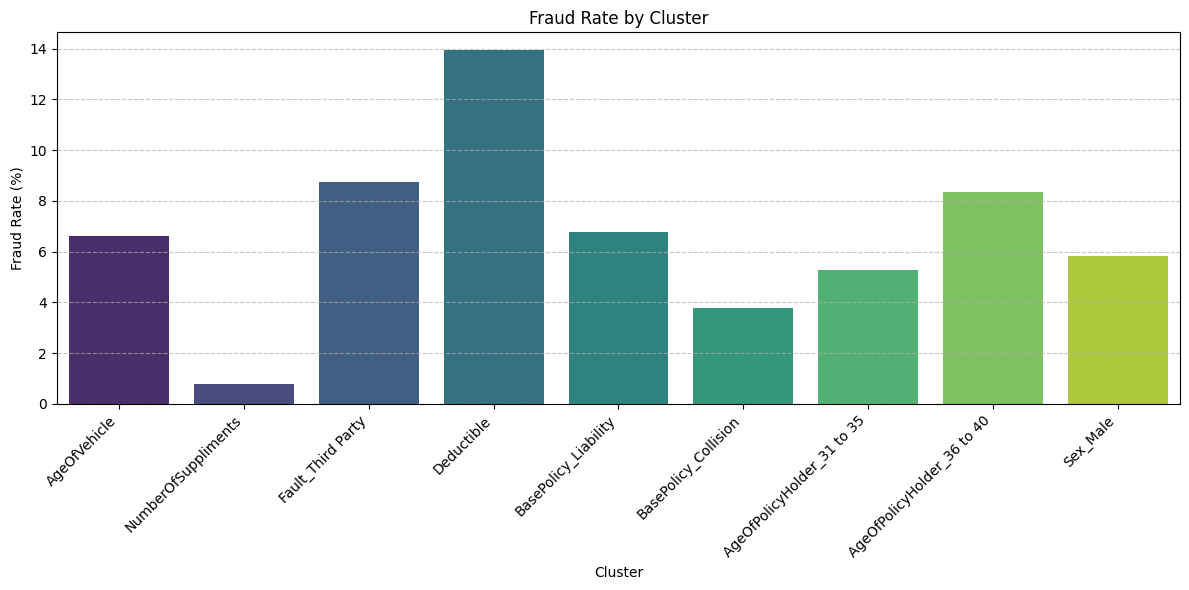

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map cluster index -> descriptive name
cluster_names = {
    0: "AgeOfVehicle",
    1: "NumberOfSuppliments",
    2: "Fault_Third Party",
    3: "Deductible",
    4: "BasePolicy_Liability",
    5: "BasePolicy_Collision",
    6: "AgeOfPolicyHolder_31 to 35",
    7: "AgeOfPolicyHolder_36 to 40",
    8: "Sex_Male",
    9: "AccidentArea_Urban",
    10: "PolicyType_Sport - Collision",
    11: "PoliceReportFiled_Yes",
}

# 1. Fraud Rate by Cluster Bar Chart

x_labels = [cluster_names.get(i, str(i)) for i in cluster_summary.index]

plt.figure(figsize=(12, 6))
sns.barplot(x=x_labels, y='Fraud_Rate', data=cluster_summary, palette='viridis')
plt.title('Fraud Rate by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1093/2694962037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_summary.index, y='Number_of_Claims', data=cluster_summary, palette='magma')


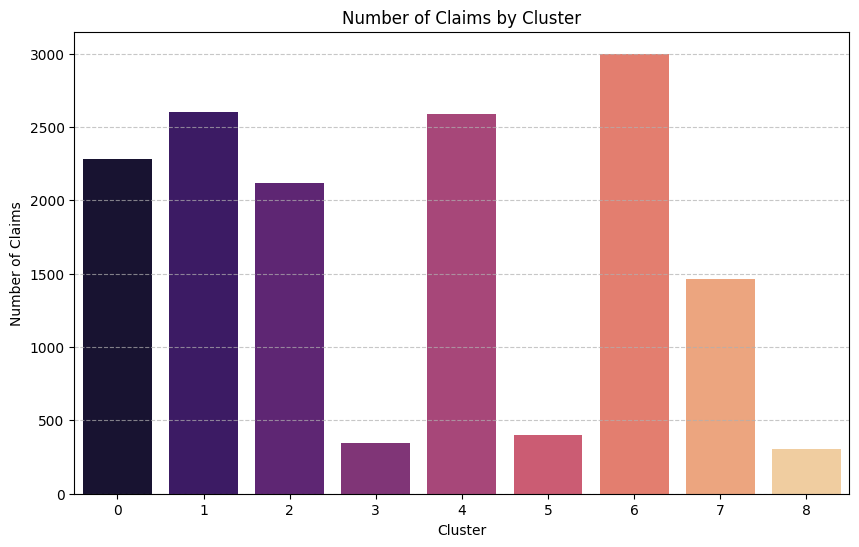

In [ ]:
# 2. Number of Claims by Cluster Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(x=cluster_summary.index, y='Number_of_Claims', data=cluster_summary, palette='magma')
plt.title('Number of Claims by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Claims')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

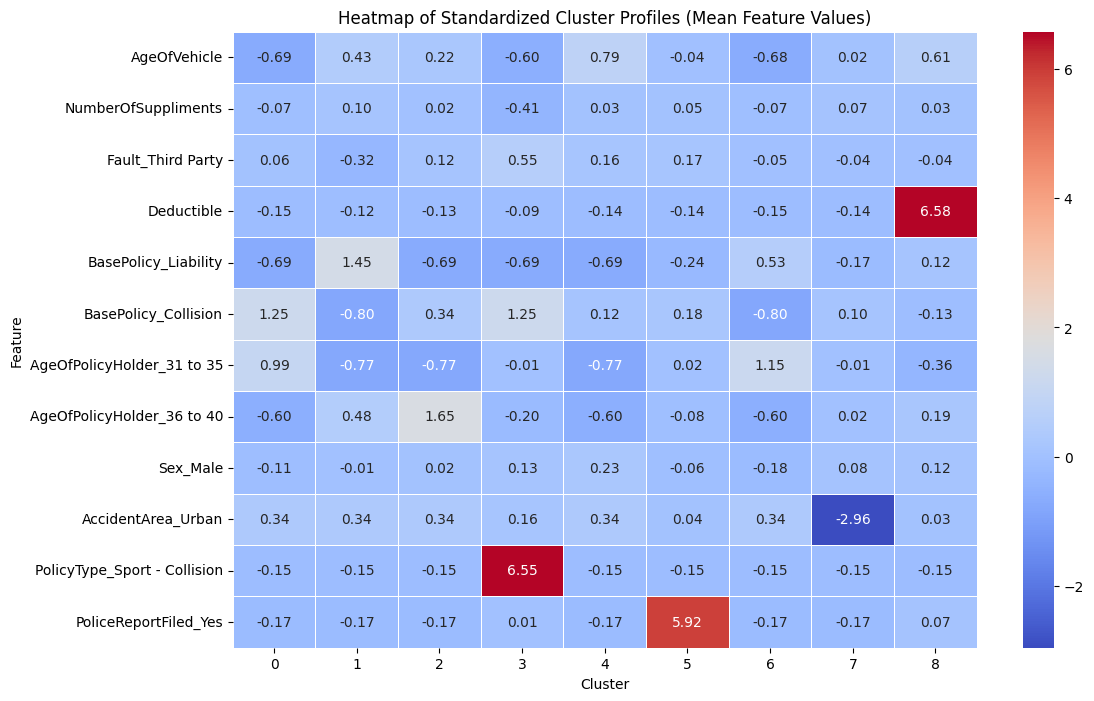

In [ ]:
# 3. Heatmap of Cluster Profiles
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_profile.T, cmap='coolwarm', annot=True, fmt=".2f", linewidths=.5)
plt.title('Heatmap of Standardized Cluster Profiles (Mean Feature Values)')
plt.xlabel('Cluster')
plt.ylabel('Feature')
plt.yticks(rotation=0)
plt.show()

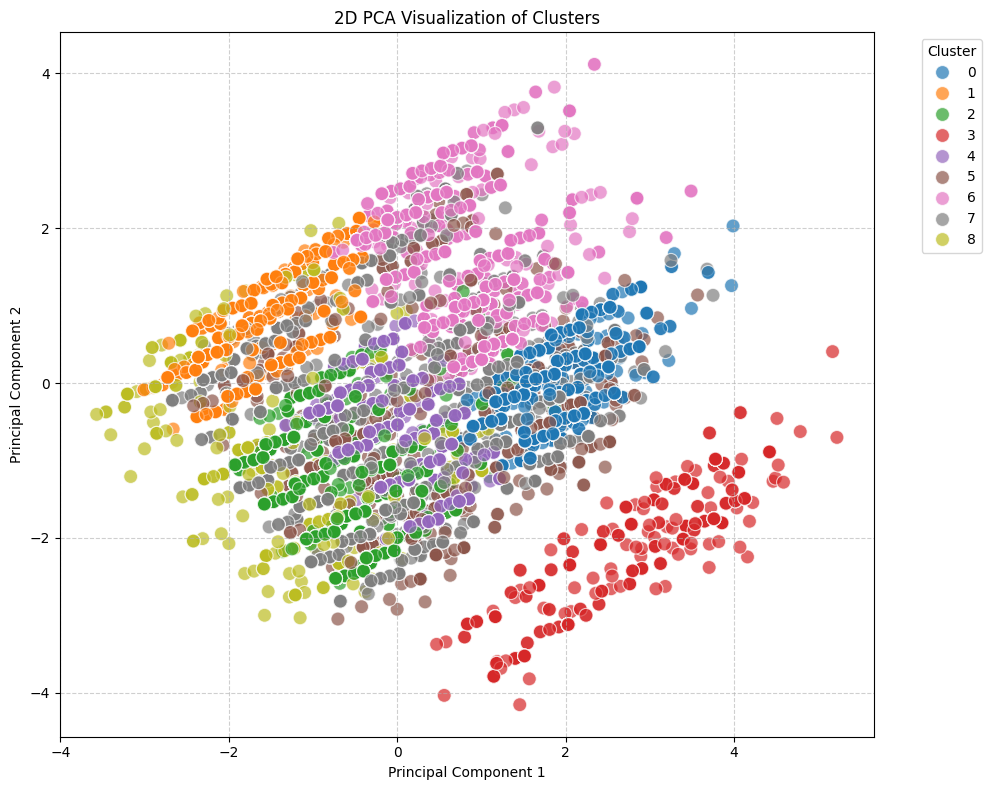

In [ ]:
from sklearn.decomposition import PCA

# 4. 2D PCA Visualization of the 9 Clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster.drop(columns=['Cluster'])) # Drop the 'Cluster' column before PCA

pca_df = pd.DataFrame(data=X_pca, columns=['Principal Component 1', 'Principal Component 2'])
pca_df['Cluster'] = X_cluster['Cluster'].values

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    data=pca_df,
    palette='tab10',
    s=100,
    alpha=0.7
)
plt.title('2D PCA Visualization of Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### K-Means Inference Report

K-Means clustering was employed to segment claims based on key variables identified across our predictive models (Logistic Regression, Decision Tree, and Random Forest). The goal was to uncover natural groupings within the data that might correspond to different risk profiles or claim characteristics, which can be useful for targeted fraud detection strategies.

We selected **K = 9** as the optimal number of clusters. This decision was primarily supported by the **Silhouette Score analysis**, which yielded the highest score of **0.2254** for 9 clusters. While the Elbow Method showed a subtle bend, the Silhouette Score offered a more direct metric for cluster cohesion and separation, indicating that 9 clusters provide the most distinct and well-defined groups.

The Silhouette Score of **0.2254** indicates that while the clusters are somewhat distinct from each other, they still exhibit **relatively limited separation**. A score closer to 1 would suggest highly distinct and well-separated clusters, while a score near 0 or negative would imply overlapping or poorly defined clusters. Therefore, while K-Means has provided valuable segmentation, it's important to acknowledge that the identified clusters may not be perfectly isolated, and there might be some overlap in their characteristics. This limitation suggests that the clustering provides broad segments rather than highly granular, perfectly separated groups, which is a common occurrence in complex, real-world datasets.

### 5. Final Model Comparison

In [ ]:
model_comparison_results = []

# Add Statsmodels Logistic Regression results (from comparison_df_sm)
for index, row in comparison_df_sm.iterrows():
    model_comparison_results.append({
        'Model': row['Model'],
        'Accuracy': row['Accuracy'],
        'Precision (Class 1)': row['Precision (Class 1)'],
        'Recall (Class 1)': row['Recall (Class 1)'],
        'F1-Score (Class 1)': row['F1-Score (Class 1)'],
        'ROC AUC': row['ROC AUC']
    })

# Add Decision Tree results
model_comparison_results.append({
    'Model': 'Decision Tree',
    'Accuracy': dt_accuracy,
    'Precision (Class 1)': dt_precision,
    'Recall (Class 1)': dt_recall,
    'F1-Score (Class 1)': dt_f1,
    'ROC AUC': dt_roc_auc
})

# Add Random Forest results
model_comparison_results.append({
    'Model': 'Random Forest',
    'Accuracy': rf_accuracy,
    'Precision (Class 1)': rf_precision,
    'Recall (Class 1)': rf_recall,
    'F1-Score (Class 1)': rf_f1,
    'ROC AUC': rf_roc_auc
})

final_comparison_df = pd.DataFrame(model_comparison_results)

print("\n--- Consolidated Model Comparison Table ---")
display(final_comparison_df.set_index('Model').round(4))


--- Consolidated Model Comparison Table ---


,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC AUC
Model,,,,,
Statsmodels Original (No SMOTE),0.9411,0.0000,0.0000,0.0000,0.7844
Statsmodels SMOTE (50:50),0.6189,0.1214,0.8764,0.2133,0.7846
Statsmodels SMOTE (45:55),0.8281,0.1597,0.4494,0.2356,0.7843
Statsmodels SMOTE (55:45),0.7536,0.1372,0.6011,0.2234,0.7848
Decision Tree,0.9404,0.4615,0.0674,0.1176,0.7637
Random Forest,0.9394,0.3913,0.0506,0.0896,0.7887


### Interpretation of Model Trade-offs for Fraud Detection

The comparison table reveals critical trade-offs, especially given the class imbalance in our fraud detection problem where fraudulent claims are a minority class.

*   **Accuracy vs. Fraud Detection Metrics:** Models like the 'Statsmodels Original (No SMOTE)', Decision Tree, and Random Forest show high accuracy (around 0.94). However, this high accuracy is misleading because the models are heavily biased towards the majority non-fraudulent class. Their 'Recall (Class 1)' is extremely low (0.00-0.07), meaning they fail to identify most actual fraudulent claims. In fraud detection, **Recall** is often paramount, as missing a fraudulent case can be very costly.

*   **Impact of SMOTE:** Applying SMOTE significantly boosts 'Recall (Class 1)' for Logistic Regression models. For instance, 'Statsmodels SMOTE (50:50)' achieves a recall of 0.8764, which is a substantial improvement over the original model's 0.00. However, this comes at the cost of 'Precision (Class 1)' (0.1214). This means that while the model catches more fraud, a higher proportion of its 'fraud' predictions are actually false positives. The `F1-Score`, which balances Precision and Recall, shows that SMOTE-enhanced Logistic Regression models (e.g., 0.2133 for 50:50) generally outperform the tree-based models and the original Logistic Regression in overall fraud detection capability.

*   **ROC AUC:** The ROC AUC scores (ranging from 0.76 to 0.79) indicate that all models have some discriminatory power between the classes. However, a good ROC AUC alone doesn't guarantee practical utility in imbalanced scenarios, especially if the decision threshold leads to poor recall or precision at the operating point.

*   **Trade-off between Recall and Precision:** In fraud detection, the business objective dictates this trade-off. If the cost of missing fraud (false negative) is very high, models with higher recall (like Logistic Regression with SMOTE) are preferred, even if they result in more false alarms (lower precision). Conversely, if investigating false alarms is expensive, a higher precision might be sought.

In summary, for fraud detection where identifying as many fraudulent cases as possible is critical, models incorporating **SMOTE** (specifically, 'Statsmodels SMOTE (50:50)') appear to be the most effective, despite their lower precision compared to models trained on imbalanced data. The high accuracy of models like Decision Tree and Random Forest is deceptive in this imbalanced context.

### 6. Model Diagnostics

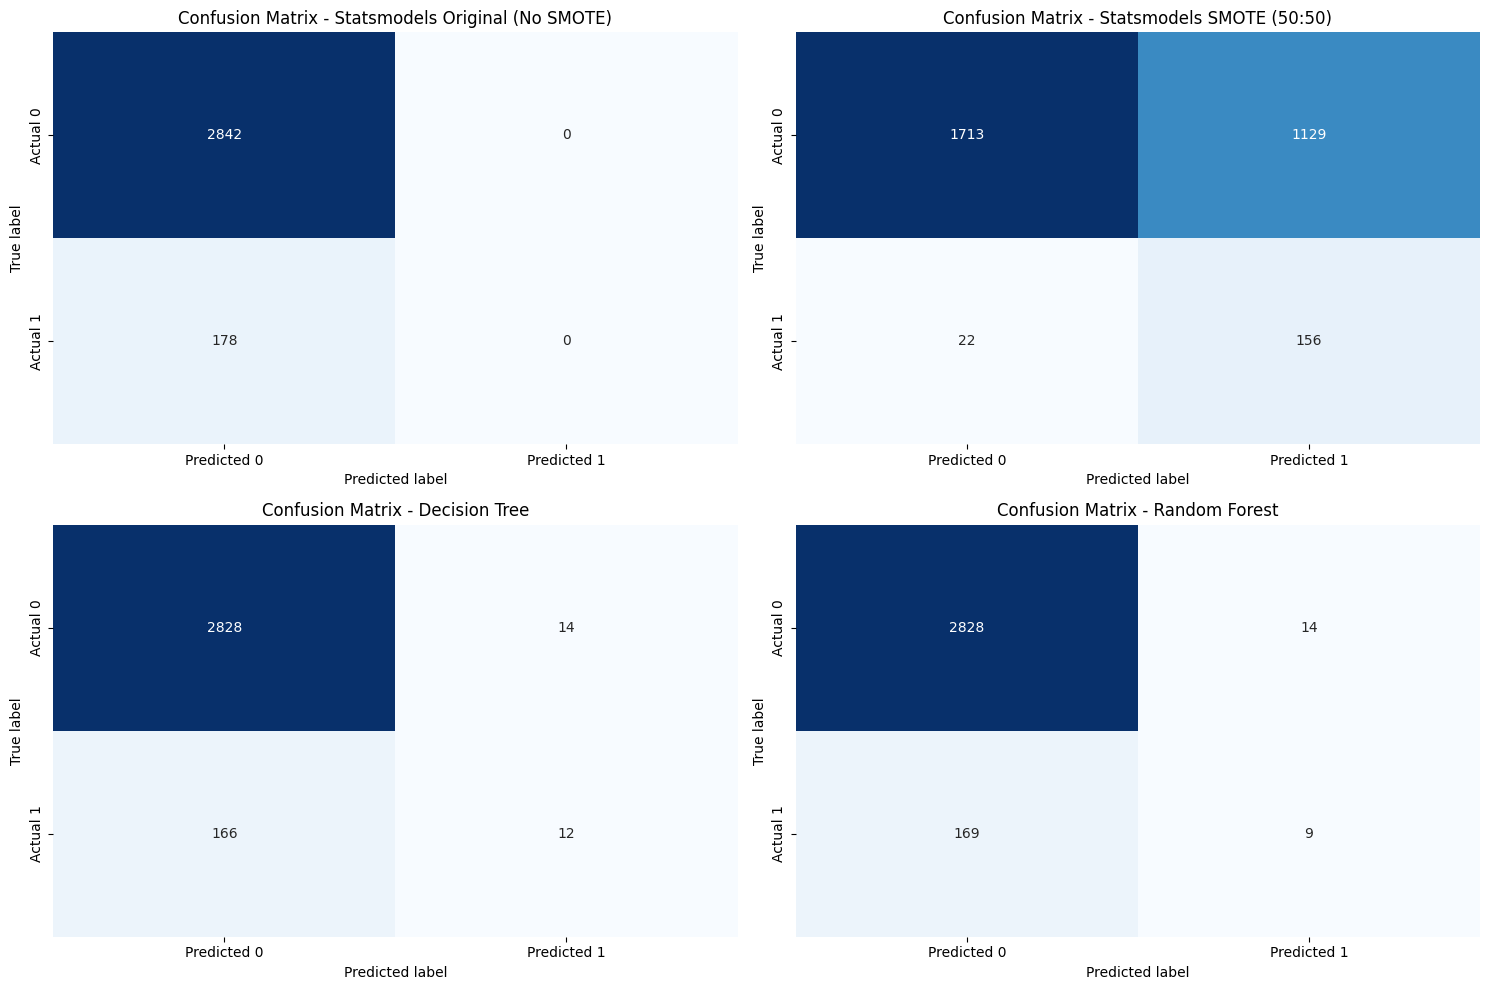

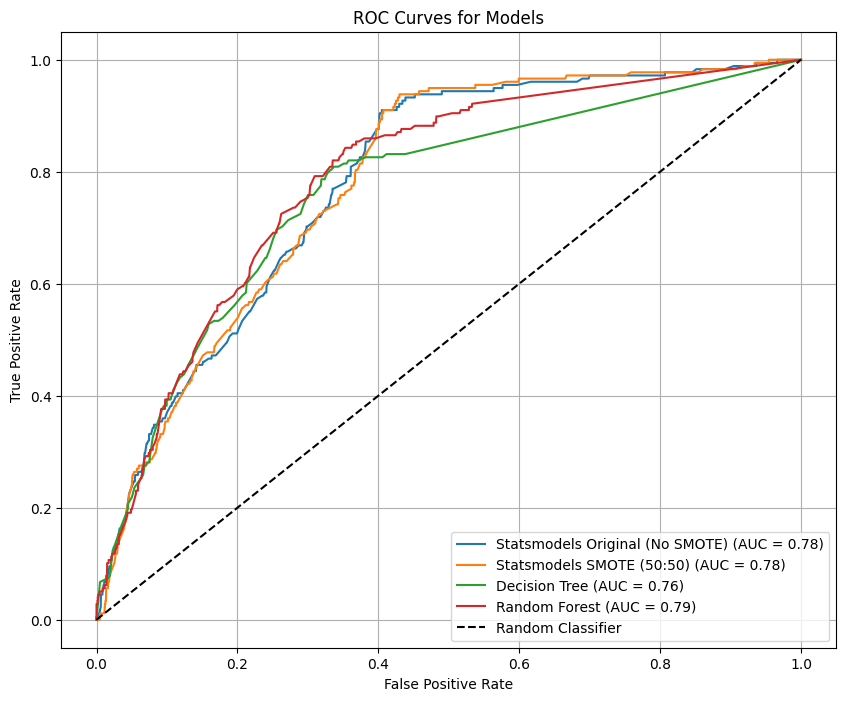

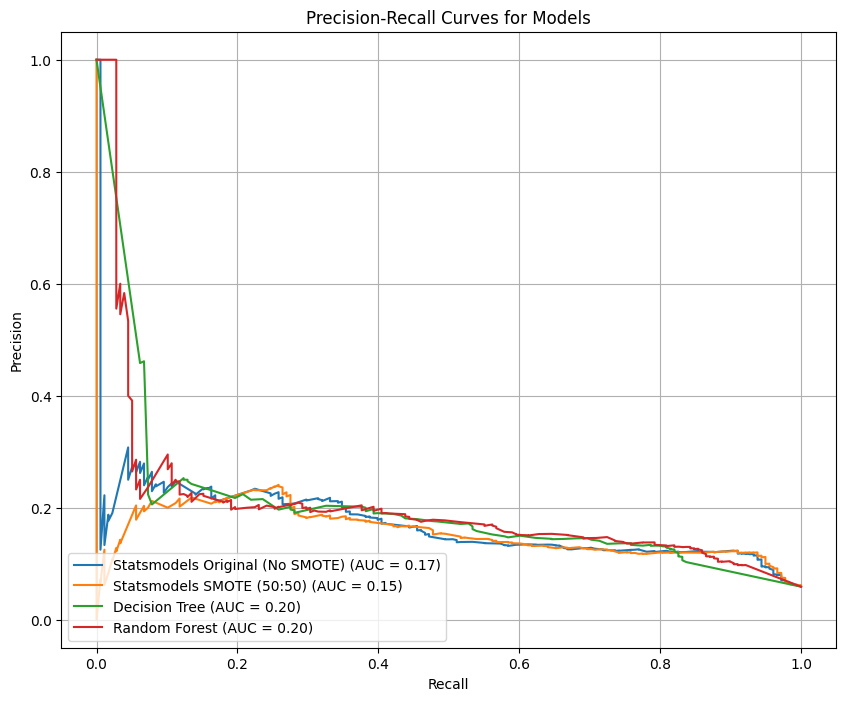

In [ ]:
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Consolidate model predictions and labels for easier plotting
model_diagnostics_data = [
    {
        'name': 'Statsmodels Original (No SMOTE)',
        'y_true': y_test,
        'y_pred': y_pred_original,
        'y_proba': y_pred_proba_original
    },
    {
        'name': 'Statsmodels SMOTE (50:50)',
        'y_true': y_test,
        'y_pred': y_pred, # y_pred from the last Statsmodels SMOTE 50:50 model
        'y_proba': y_pred_proba # y_pred_proba from the last Statsmodels SMOTE 50:50 model
    },
    {
        'name': 'Decision Tree',
        'y_true': y_test,
        'y_pred': y_pred_dt,
        'y_proba': y_prob_dt
    },
    {
        'name': 'Random Forest',
        'y_true': y_test,
        'y_pred': y_pred_rf,
        'y_proba': y_prob_rf
    }
]

# --- Confusion Matrices ---
plt.figure(figsize=(15, 10))
for i, model_data in enumerate(model_diagnostics_data):
    plt.subplot(2, 2, i + 1)
    cm = confusion_matrix(model_data['y_true'], model_data['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    plt.title(f'Confusion Matrix - {model_data["name"]}')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

# --- ROC Curves ---
plt.figure(figsize=(10, 8))
for model_data in model_diagnostics_data:
    fpr, tpr, _ = roc_curve(model_data['y_true'], model_data['y_proba'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_data["name"]} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# --- Precision-Recall Curves ---
plt.figure(figsize=(10, 8))
for model_data in model_diagnostics_data:
    precision, recall, _ = precision_recall_curve(model_data['y_true'], model_data['y_proba'])
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f'{model_data["name"]} (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves for Models')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

### Interpretation of Confusion Matrix Components and Importance of Metrics in Fraud Detection

**Understanding the Confusion Matrix:**
A confusion matrix provides a detailed breakdown of a classification model's performance by showing the number of correct and incorrect predictions made by the classifier, broken down by each class.

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly identified a fraudulent claim).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identified a non-fraudulent claim).
*   **False Positives (FP):** The model incorrectly predicted a positive outcome (e.g., incorrectly flagged a legitimate claim as fraudulent). Also known as a Type I error.
*   **False Negatives (FN):** The model incorrectly predicted a negative outcome (e.g., failed to identify an actual fraudulent claim). Also known as a Type II error.

**Why Recall, Precision, and F1-score are Crucial for Fraud Detection:**

In fraud detection, datasets are typically highly imbalanced, meaning there are far fewer fraudulent cases than legitimate ones. In such scenarios, accuracy alone can be misleading, and other metrics become vital:

*   **Recall (Sensitivity or True Positive Rate):**
    *   **Formula:** TP / (TP + FN)
    *   **Meaning:** The proportion of actual fraudulent claims that were correctly identified by the model. It tells us how many of the 'fraudulent' claims the model 'recalled'.
    *   **Importance in Fraud Detection:** High recall is critical because the cost of missing a fraudulent transaction (False Negative) is often very high, potentially leading to significant financial losses or damage to reputation. It's generally preferable to have a higher recall, even if it means tolerating some false positives that require manual review.

*   **Precision (Positive Predictive Value):**
    *   **Formula:** TP / (TP + FP)
    *   **Meaning:** The proportion of predicted fraudulent claims that were actually fraudulent. It tells us, among all claims the model flagged as 'fraud', how many were correct.
    *   **Importance in Fraud Detection:** High precision is important because false positives (flagging a legitimate claim as fraud) lead to operational costs (e.g., manual investigation, customer inconvenience, negative customer experience). While recall is often prioritized, a very low precision can make the model impractical due to an overwhelming number of false alarms.

*   **F1-score:**
    *   **Formula:** 2 * (Precision * Recall) / (Precision + Recall)
    *   **Meaning:** The harmonic mean of precision and recall. It provides a single score that balances both metrics.
    *   **Importance in Fraud Detection:** The F1-score is useful when you need to strike a balance between precision and recall, especially in imbalanced datasets. A high F1-score indicates that the model is performing well in both identifying true positives and minimizing false positives and negatives, which is a desirable characteristic for a robust fraud detection system.

In summary, while accuracy might seem high due to the prevalence of legitimate transactions, it can mask a poor ability to detect the rare, but critical, fraudulent cases. Therefore, a careful evaluation using recall, precision, and F1-score is essential to build an effective fraud detection model.

### 7. Feature Importance / Significant Variable Summary

This section consolidates the significant variables identified by each model, distinguishing between statistical significance (Logistic Regression) and feature importance (tree-based models).

In [ ]:
import pandas as pd

# Extract Logistic Regression (Statsmodels SMOTE 50:50) coefficients and p-values
# We'll use the final_smote_model from the Statsmodels Logistic Regression section
log_reg_summary = final_smote_model.summary2().tables[1]
log_reg_significant_vars = log_reg_summary[log_reg_summary['P>|z|'] < 0.05].index.tolist()
# Exclude 'const' from the list of significant variables
if 'const' in log_reg_significant_vars:
    log_reg_significant_vars.remove('const')

# Decision Tree Feature Importance
dt_feature_importance_df = pd.DataFrame({
    'Feature': X_train_dt.columns,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)
dt_top_features = dt_feature_importance_df[dt_feature_importance_df['Importance'] > 0].head(10)['Feature'].tolist() # Top 10 non-zero importance

# Random Forest Feature Importance
rf_feature_importance_df = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)
rf_top_features = rf_feature_importance_df[rf_feature_importance_df['Importance'] > 0].head(10)['Feature'].tolist() # Top 10 non-zero importance

# Combine all unique features
all_features = sorted(list(set(log_reg_significant_vars + dt_top_features + rf_top_features)))

# Create the summary table
final_feature_summary = pd.DataFrame({'Feature': all_features})

final_feature_summary['Logistic Regression (SMOTE 50:50)'] = final_feature_summary['Feature'].apply(lambda x: 'Statistically Significant' if x in log_reg_significant_vars else '-')
final_feature_summary['Decision Tree (Feature Importance)'] = final_feature_summary['Feature'].apply(lambda x: 'Important' if x in dt_top_features else '-')
final_feature_summary['Random Forest (Feature Importance)'] = final_feature_summary['Feature'].apply(lambda x: 'Important' if x in rf_top_features else '-')

print("\n--- Consolidated Feature Importance / Significant Variable Summary ---")
display(final_feature_summary)


print("\n--- Interpretation ---")
print("The table above summarizes the key features identified by each model:")
print("- **Statistically Significant (Logistic Regression):** These are variables whose coefficients are significantly different from zero, implying a linear relationship with the log-odds of fraud found, after controlling for other variables. Their p-values are less than 0.05.")
print("- **Important (Decision Tree/Random Forest):** These are features that contribute most to reducing impurity (e.g., Gini impurity or entropy) in the tree-based models, thus having a strong impact on the model's predictive power. The importance is a relative measure based on how much the splits on a feature reduce the impurity.")
print("It's important to note the distinction: statistical significance in Logistic Regression speaks to the reliability of a feature's effect in a linear model, while feature importance in tree-based models quantifies a feature's utility in making splits that improve prediction accuracy within those models. Often, features found to be statistically significant in one type of model are also found to be important in another, providing stronger evidence of their predictive power.")


--- Consolidated Feature Importance / Significant Variable Summary ---


,Feature,Logistic Regression (SMOTE 50:50),Decision Tree (Feature Importance),Random Forest (Feature Importance)
0,AccidentArea_Urban,Statistically Significant,Important,Important
1,AgeOfPolicyHolder_31 to 35,Statistically Significant,Important,Important
2,AgeOfPolicyHolder_36 to 40,Statistically Significant,Important,Important
3,AgeOfVehicle,Statistically Significant,Important,Important
4,BasePolicy_Collision,Statistically Significant,Important,Important
5,BasePolicy_Liability,Statistically Significant,Important,Important
6,Deductible,Statistically Significant,Important,Important
7,Fault_Third Party,Statistically Significant,Important,Important
8,Make_VW,Statistically Significant,-,-
9,NumberOfSuppliments,Statistically Significant,Important,Important



--- Interpretation ---
The table above summarizes the key features identified by each model:
- **Statistically Significant (Logistic Regression):** These are variables whose coefficients are significantly different from zero, implying a linear relationship with the log-odds of fraud found, after controlling for other variables. Their p-values are less than 0.05.
- **Important (Decision Tree/Random Forest):** These are features that contribute most to reducing impurity (e.g., Gini impurity or entropy) in the tree-based models, thus having a strong impact on the model's predictive power. The importance is a relative measure based on how much the splits on a feature reduce the impurity.
It's important to note the distinction: statistical significance in Logistic Regression speaks to the reliability of a feature's effect in a linear model, while feature importance in tree-based models quantifies a feature's utility in making splits that improve prediction accuracy within those models. Oft